#### CK
#### Date

## Final Project

## Background

After looking at a ton of different datasets I decided to go with some NYC open data. NYC has CSV and APIs available to pull data. Since I wanted to make sure I was using the same data and not coming up with different results. Especially since we will want to make sure we clean and transform our data.

### Dataset Selection

I picked what I hope will be a very robust dataset - New York Police Department Arrest Data. The dataset I pulled has 212,487 rows and 19 columns, so definitely a good sized set. I would say it meets the ***adequacy check***.
This data is from the New York City Police Department and comprises what the department uses to complete their reports. The variable names seem clear and the available data descriptions ensures clarity. I would say this this meets the ***data integrity*** check.

**URL:** https://data.cityofnewyork.us/Public-Safety/NYPD-Arrest-Data-Year-to-Date-/uip8-fykc/about_data 

#### Data Descriptions

| Column Name | Description | API Field Name | Data Type |
| :--- | :--- | :--- | :--- |
| ARREST_KEY | Randomly generated persistent ID for each arrest | arrest_key | Text |
| ARREST_DATE | Exact date of arrest for the reported event | arrest_date | Floating Timestamp |
| PD_CD | Three digit internal classification code (more granular than Key Code) | pd_cd | Number |
| PD_DESC | Description of internal classification corresponding with PD code | pd_desc | Text |
| KY_CD | Three digit internal classification code (more general category than PD code) | ky_cd | Number |
| OFNS_DESC | Description of internal classification corresponding with KY code | ofns_desc | Text |
| LAW_CODE | Law code charges corresponding to the NYS Penal Law, VTL and other various local laws | law_code | Text |
| LAW_CAT_CD | Level of offense: felony, misdemeanor, violation | law_cat_cd | Text |
| ARREST_BORO | Borough of arrest. B(Bronx), S(Staten Island), K(Brooklyn), M(Manhattan), Q(Queens) | arrest_boro | Text |
| ARREST_PRECINCT | Precinct where the arrest occurred | arrest_precinct | Number |
| JURISDICTION_CODE | Jurisdiction responsible for arrest. 0(Patrol), 1(Transit), 2(Housing), 3+ (Non-NYPD) | jurisdiction_code | Number |
| AGE_GROUP | Perpetrator’s age within a category | age_group | Text |
| PERP_SEX | Perpetrator’s sex description | perp_sex | Text |
| PERP_RACE | Perpetrator’s race description | perp_race | Text |
| X_COORD_CD | Midblock X-coordinate for New York State Plane Coordinate System | x_coord_cd | Number |

In [4]:
# Load the data
import pandas as pd
arrests = pd.read_csv('NYPD_arrest_data.csv')

# Display the first few rows to verify the schema matches your table
arrests.head()

# Quick check of the data types
print(arrests.dtypes)

ARREST_KEY             int64
ARREST_DATE           object
PD_CD                  int64
PD_DESC               object
KY_CD                float64
OFNS_DESC             object
LAW_CODE              object
LAW_CAT_CD            object
ARREST_BORO           object
ARREST_PRECINCT        int64
JURISDICTION_CODE      int64
AGE_GROUP             object
PERP_SEX              object
PERP_RACE             object
X_COORD_CD             int64
Y_COORD_CD             int64
Latitude             float64
Longitude            float64
Location              object
dtype: object


Now we can check the data itself.
Just by looking here we can already see some things we'll want to change in the data like the ARREST_DATE is an object- we'll want that to be a date.

In [23]:
arrests.head()

,ARREST_KEY,ARREST_DATE,PD_CD,PD_DESC,KY_CD,OFNS_DESC,LAW_CODE,LAW_CAT_CD,ARREST_BORO,ARREST_PRECINCT,...,PERP_RACE,X_COORD_CD,Y_COORD_CD,Latitude,Longitude,Location,ARREST_MONTH,DAY_OF_WEEK,AGE_GROUP_ENCODED,BORO_NAMED
0,298760433,2025-01-02,782,"WEAPONS, POSSESSION, ETC",236.0,DANGEROUS WEAPONS,PL 2650101,M,Q,115,...,BLACK,NaN,NaN,0.000000,0.000000,POINT (0 0),January,Thursday,-1,Queens
1,299030225,2025-01-07,105,STRANGULATION 1ST,106.0,FELONY ASSAULT,PL 1211200,F,M,28,...,BLACK,-0.373995,0.880338,40.808558,-73.952357,POINT (-73.952357 40.808558),January,Tuesday,2,Manhattan
2,299127494,2025-01-08,849,"NY STATE LAWS,UNCLASSIFIED VIO",677.0,OTHER STATE LAWS,LOC00000V0,V,K,81,...,WHITE,NaN,NaN,0.000000,0.000000,POINT (0 0),January,Wednesday,-1,Brooklyn
3,299188536,2025-01-09,259,"CRIMINAL MISCHIEF,UNCLASSIFIED 4",351.0,CRIMINAL MISCHIEF & RELATED OF,PL 1450001,M,M,7,...,BLACK,NaN,NaN,0.000000,0.000000,POINT (0 0),January,Thursday,-1,Manhattan
4,299533742,2025-01-16,155,RAPE 2,104.0,RAPE,PL 1303001,F,K,81,...,BLACK,-0.004277,-0.570573,40.689464,-73.924029,POINT (-73.9240290899499 40.6894642952604),January,Thursday,1,Brooklyn


## Data Cleaning and Preparation

First we want to ensure that the dates are actually classified as dates, so we'll make the ARREST_DATE variable a true datetime with pandas. This will allow us to use it as a date and not just as a string.

In [5]:
arrests['ARREST_DATE'] = pd.to_datetime(arrests['ARREST_DATE'])

# check the update (should show datetime64[ns])
print(f"New Data Type: {arrests['ARREST_DATE'].dtype}")

New Data Type: datetime64[ns]


Now that we have that we can do more with the dates. We can start by making new columns that will include the month and day of the week based on the `ARREST_DATE`

In [6]:
# add a month and week column
arrests['ARREST_MONTH'] = arrests['ARREST_DATE'].dt.month_name()
arrests['DAY_OF_WEEK'] = arrests['ARREST_DATE'].dt.day_name()

# Show the first few rows with the new time features
arrests[['ARREST_DATE', 'ARREST_MONTH', 'DAY_OF_WEEK']].head()

,ARREST_DATE,ARREST_MONTH,DAY_OF_WEEK
0,2025-01-02,January,Thursday
1,2025-01-07,January,Tuesday
2,2025-01-08,January,Wednesday
3,2025-01-09,January,Thursday
4,2025-01-16,January,Thursday


By doing these conversions for date type we will be able to perform time-based operations that wouldn't work on standard text strings.
We've now enabled:
- sorting: correctly ordering arrests from oldest to newest
- resampling: easily group data by week or month to see trends
- filtering: select specific date ranges

***Missing Data***
One of the things I'm worried about is missing data. I definitely see Lat/Lons that are 0.000 (clearly not entered), empty coordinates, age, the perpetrator's sex, and location not entered. 
There are a few choices that I have here, either disregard data that is missing, but I feel like that would impact my analysis, or I can handle them by coding them with values so I don't lose the data but will have a visual of where I am missing things. I think that is the way I want to handle it for this analysis so I'll work through that as I clean and prepare the data.

Since AGE_GROUP is ordinal data and has a natural progression (younger to older), we can use **Label Encoding** which will make any use of machine learning models, like Linear Regression, easier later since they treat numbers as having magnitude. 

We will do a manual map instead of using the `LabelEncoder` from Scikit-Learn since it has some possible issues (like assigning numbers alphabetically rather than chronologically).

In [7]:
# first we will convert the (null) to actual NumPy NaNs
import numpy as np
arrests['AGE_GROUP'] = arrests['AGE_GROUP'].replace('(null)', np.nan)

# Define the chronological order
age_mapping = {
    '<18': 0,
    '18-24': 1,
    '25-44': 2,
    '45-64': 3,
    '65+': 4
}

# create a new column an apply the mapping
arrests['AGE_GROUP_ENCODED'] = arrests['AGE_GROUP'].map(age_mapping)

# Handle any unexpected values (like the nulls we see) by filling with -1 
arrests['AGE_GROUP_ENCODED'] = arrests['AGE_GROUP_ENCODED'].fillna(-1).astype(int)

# Verify the results
print(arrests['AGE_GROUP_ENCODED'].value_counts())
print("-" * 50) 
print(arrests[['AGE_GROUP', 'AGE_GROUP_ENCODED']].drop_duplicates().sort_values('AGE_GROUP_ENCODED'))

-1    91878
 2    70897
 3    26545
 1    16801
 0     3840
 4     2525
Name: AGE_GROUP_ENCODED, dtype: int64
--------------------------------------------------
   AGE_GROUP  AGE_GROUP_ENCODED
0        NaN                 -1
47       <18                  0
4      18-24                  1
1      25-44                  2
13     45-64                  3
55       65+                  4


I can see that we have over 91,000 values that are missing an age. I'll need to make a decision if I want to keep these or not.

Let's keep going with creating new variables as needed. Having the real borough names will be easier.

In [8]:
boro_map = {'B': 'Bronx', 'S': 'Staten Island', 'K': 'Brooklyn', 'M': 'Manhattan', 'Q': 'Queens'}
arrests['BORO_NAMED'] = arrests['ARREST_BORO'].map(boro_map)
arrests.head()

,ARREST_KEY,ARREST_DATE,PD_CD,PD_DESC,KY_CD,OFNS_DESC,LAW_CODE,LAW_CAT_CD,ARREST_BORO,ARREST_PRECINCT,...,PERP_RACE,X_COORD_CD,Y_COORD_CD,Latitude,Longitude,Location,ARREST_MONTH,DAY_OF_WEEK,AGE_GROUP_ENCODED,BORO_NAMED
0,298760433,2025-01-02,782,"WEAPONS, POSSESSION, ETC",236.0,DANGEROUS WEAPONS,PL 2650101,M,Q,115,...,BLACK,0,0,0.000000,0.000000,POINT (0 0),January,Thursday,-1,Queens
1,299030225,2025-01-07,105,STRANGULATION 1ST,106.0,FELONY ASSAULT,PL 1211200,F,M,28,...,BLACK,997439,233857,40.808558,-73.952357,POINT (-73.952357 40.808558),January,Tuesday,2,Manhattan
2,299127494,2025-01-08,849,"NY STATE LAWS,UNCLASSIFIED VIO",677.0,OTHER STATE LAWS,LOC00000V0,V,K,81,...,WHITE,0,0,0.000000,0.000000,POINT (0 0),January,Wednesday,-1,Brooklyn
3,299188536,2025-01-09,259,"CRIMINAL MISCHIEF,UNCLASSIFIED 4",351.0,CRIMINAL MISCHIEF & RELATED OF,PL 1450001,M,M,7,...,BLACK,0,0,0.000000,0.000000,POINT (0 0),January,Thursday,-1,Manhattan
4,299533742,2025-01-16,155,RAPE 2,104.0,RAPE,PL 1303001,F,K,81,...,BLACK,1005319,190473,40.689464,-73.924029,POINT (-73.9240290899499 40.6894642952604),January,Thursday,1,Brooklyn


Checking missing values per borough:
         Borough  Percent_Missing
0          Bronx        52.817696
2      Manhattan        47.131365
1       Brooklyn        43.805928
3         Queens        31.543172
4  Staten Island        24.591972


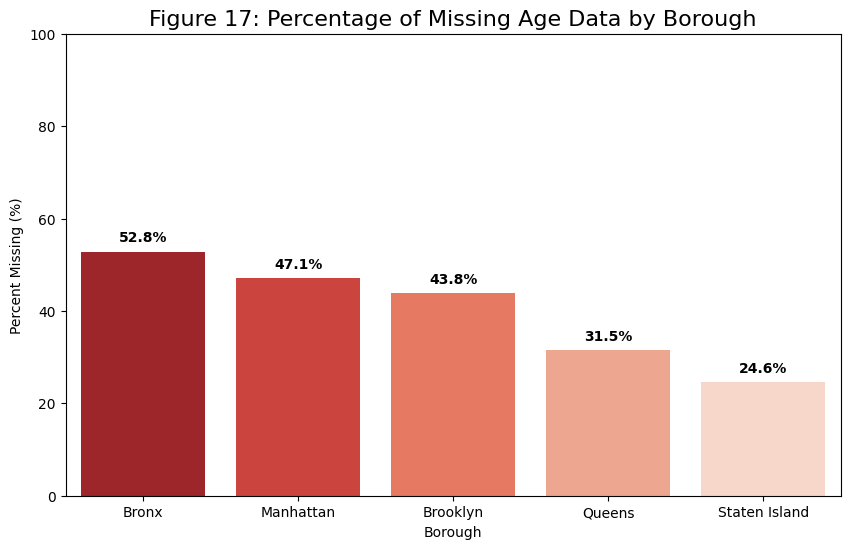

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Standardize the Borough names first
boro_map = {'B': 'Bronx', 'S': 'Staten Island', 'K': 'Brooklyn', 'M': 'Manhattan', 'Q': 'Queens'}
temp_df = arrests.copy()
temp_df['BORO_NAMED'] = temp_df['BORO_NAMED'].replace(boro_map)

# Identify missing values (Checks for NaN, '(null)', and empty strings)
# This creates a True/False column for "Is this record missing an age?"
temp_df['is_missing_age'] = (
    temp_df['AGE_GROUP'].isna() | 
    (temp_df['AGE_GROUP'] == '(null)') | 
    (temp_df['AGE_GROUP'] == '')
)

# Calculate Percentages
summary = temp_df.groupby('BORO_NAMED')['is_missing_age'].mean() * 100
summary = summary.reset_index().sort_values('is_missing_age', ascending=False)
summary.columns = ['Borough', 'Percent_Missing']

# debugging... since I ran sections out of order after re-starting the kernel sometimes I don't have boroughs...
# If the graph is empty, look at your terminal/output for these numbers:
print("Checking missing values per borough:")
print(summary)

# creating plot
plt.figure(figsize=(10, 6))
if not summary.empty and summary['Percent_Missing'].sum() > 0:
    ax = sns.barplot(data=summary, x='Borough', y='Percent_Missing', palette='Reds_r')
    
    # Add labels
    for p in ax.patches:
        ax.annotate(f'{p.get_height():.1f}%', 
                    (p.get_x() + p.get_width() / 2., p.get_height()), 
                    ha='center', va='bottom', fontweight='bold', xytext=(0, 5), 
                    textcoords='offset points')
    
    plt.title('Figure 17: Percentage of Missing Age Data by Borough', fontsize=16)
    plt.ylabel('Percent Missing (%)')
    plt.ylim(0, 100)
    plt.show()
else:
    print("NO MISSING VALUES FOUND. Check your column names or 'AGE_GROUP' content.")

After noting the 91,878 records that had no age (null) I wanted to validate if this was uniform across the different buroughs or if it was relatively uniform across the buroughs. The percentages for missing ages is obviously all over the place and if I simply delete all of these records I will clearly change the results to say things that are not true. To maintain the integrity of age-based calculations I should filter these out and maintain the full dataset for general geographic counts. 

This could be considered a 'non-random' pattern of missing data. It is clear to see that the Bronx has significantly more data missing than Staten Island does. 


Since I have encoded the age groups we can calculate **skewness** and **kurtosis** - I'll try this first with the encoded age group, so the age group that has all the ages,  including the missing ages that I encoded as -1. 

In [10]:
from scipy.stats import skew, kurtosis

# make sure we have no NAs that will cause an issue for skew/kurtosis
clean_age = arrests['AGE_GROUP_ENCODED'].dropna()

age_skew = skew(clean_age)
age_kurt = kurtosis(clean_age)

print(f"Age Group Skewness: {age_skew:.2f}")
print(f"Age Group Kurtosis: {age_kurt:.2f}")

Age Group Skewness: 0.06
Age Group Kurtosis: -1.63


##### Skewness - Reminder- this is the Age Encoded Data Variable
The skewness of 0.06 is very close to zero, so it provides an insight into the 'lean' of the demographic data.

* Symmetry: a value this close to zero indicates that the distribution of arrests across the encoded age categories is nearly symmetric
* Implication: there is no significant tail in the data; the arrests are not heavily weighted toward only the youngest or oldest age groups. They are distributed fairly evenly around the center of the encoded scale
* Significance: when assuming a significance level of $\alpha=0.05$, the skewness of 0.06 would cause us to fail to reject the null hypothesis of symmetry in most normality tests, confirming the distribution is balanced.

###### Kurtosis
The kurtosis value of -1.63 is more revealing than the skewness, since it describes the peak or flatness of the distribution

* Platykurtic Distribution: a negative kurtosis value indicates a platykurtic distribution. This means the distribution is flatter than a normal distribution
* Data Spread: for this NYPD arrest data, this suggests that the arrests are broadly spread across all the age categories and not highly concentrated in one specific group
* Tails: this indicates we have fewer outliers than expected in a normal curve
* Statistical Power: due to the large size of my sample this estimate for kurtosis is extremely stable. This means the Type II ($\beta$) risk is minimized and I can be confident that this 'flatness' is a real characteristic of the NYC arrest population.

Reminder that this includes all my data- even the missing rows. So I don't know if I could say this is a very fair representation of the entire dataset since the -1 (group with null values) is included in this result.

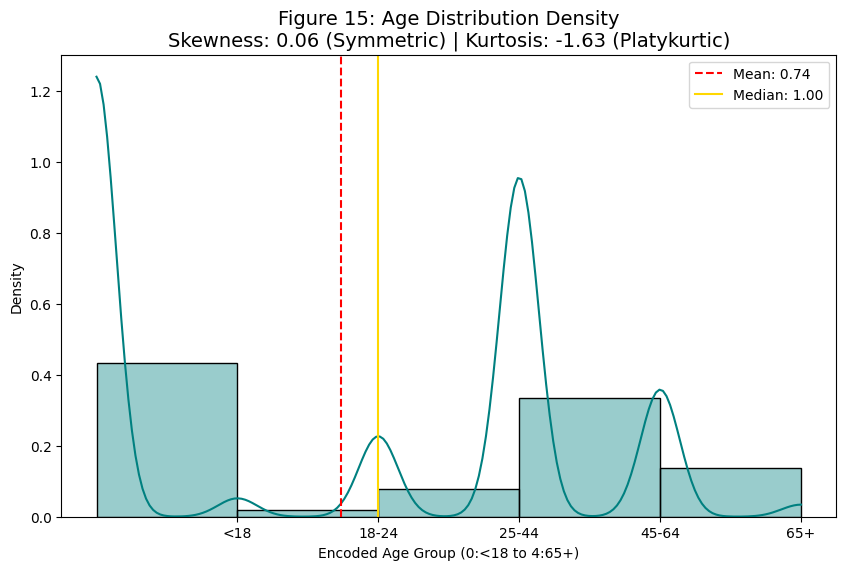

In [11]:
# I'll re-use the clean_age df from above + the skew and kurtosis numbers - but I still want mean/median
import matplotlib.pyplot as plt
import seaborn as sns

mean_age = clean_age.mean()
median_age = clean_age.median()


# creating a histogram with a density curve
plt.figure(figsize=(10, 6))
sns.histplot(clean_age, kde=True, bins=5, color='teal', stat="density", alpha=0.4)

# Add Mean and Median lines to show symmetry (Skewness)
plt.axvline(mean_age, color='red', linestyle='--', label=f'Mean: {mean_age:.2f}')
plt.axvline(median_age, color='gold', linestyle='-', label=f'Median: {median_age:.2f}')

plt.title(f'Figure 15: Age Distribution Density\nSkewness: {age_skew:.2f} (Symmetric) | Kurtosis: {age_kurt:.2f} (Platykurtic)', fontsize=14)
plt.xlabel('Encoded Age Group (0:<18 to 4:65+)')
plt.ylabel('Density')
plt.xticks(ticks=[0, 1, 2, 3, 4], labels=['<18', '18-24', '25-44', '45-64', '65+'])
plt.legend()
plt.show()

All of the above plots were made with the full age dataset-- It really looks like the -18 is really high- what I don't know yet is if those are truly under 18 or some are the unknown values throwing this off. I would like to try this again using only the data that has valid ages.

Now I'll re-do this but with the other dataframe that I have only the data that has the ages. Once I have the results of this round of skewness/kurtosis I'll be able to decide which of the values I want to use for age.

In [12]:
from scipy.stats import skew, kurtosis
import pandas as pd

# Filter out the '(null)' strings and any actual NaNs
# We use .copy() to ensure we aren't working on a "view" of the data
clean_age_df = arrests[(arrests['AGE_GROUP'].notna()) & (arrests['AGE_GROUP'] != '(null)')].copy()

# Map strings to numbers for statistical calculation
age_map = {'<18': 0, '18-24': 1, '25-44': 2, '45-64': 3, '65+': 4}
clean_age_df['AGE_NUMERIC'] = clean_age_df['AGE_GROUP'].map(age_map)

# Calculate the statistics on the numeric column
filtered_age_skew = skew(clean_age_df['AGE_NUMERIC'])
filtered_age_kurt = kurtosis(clean_age_df['AGE_NUMERIC'])

# printing out results
rows_removed = len(arrests) - len(clean_age_df)
print(f"--- Statistics After Cleaning Data ---")
print(f"Rows Removed: {rows_removed}")
print(f"Rows Retained: {len(clean_age_df)}")
print(f"Age Group Skewness: {filtered_age_skew:.2f}")
print(f"Age Group Kurtosis: {filtered_age_kurt:.2f}")

--- Statistics After Cleaning Data ---
Rows Removed: 91878
Rows Retained: 120608
Age Group Skewness: -0.25
Age Group Kurtosis: 0.79


This is what my skewness/kurtosis would look like if I did remove the rows with missing ages. 

Here my skewness of -0.25 is slightly negative/left-skewed. This means my distribution is slightly left skewed and in the context of the data, this means the 'tail' of the distribution extends towards younger age groups while the bulk of the arrests is concentrated toward the middle and older categories (25-44 and 45-64).

Since our value is between -0.5 and 0.5 the distribution is still fairly symmetrical. There is a slight lean toward older age groups but it is not a radical departure from a balanced distribution.

The kurtosis here is leptokurtic/peaked. This is a positive kurtosis and indicates a leptokurtic distribution. This is quite a significant change from my previous results. This means teh data now has a 'sharper' peak than a normal distribution.

This suggests that arrests are more heavily concentrated wtihin one or two specific age groups rather than evenly spread across all ages.

If I decided to use this data I would still have over 120,000 rows of data so my statistical power is exceptionally high. That means this 'peaked' concentration in the middle-age brackets is a true characteristic of teh 2025 arrest patterns and not just random chance. 

My determination moving forward would then be, if I am going to compare age to other values I will use the cleaned dataset that has valid ages. Since the age data is not evenly missing from the different burroughs if I am looking for area/geographic comparisons I will use the burrough and the full dataset.

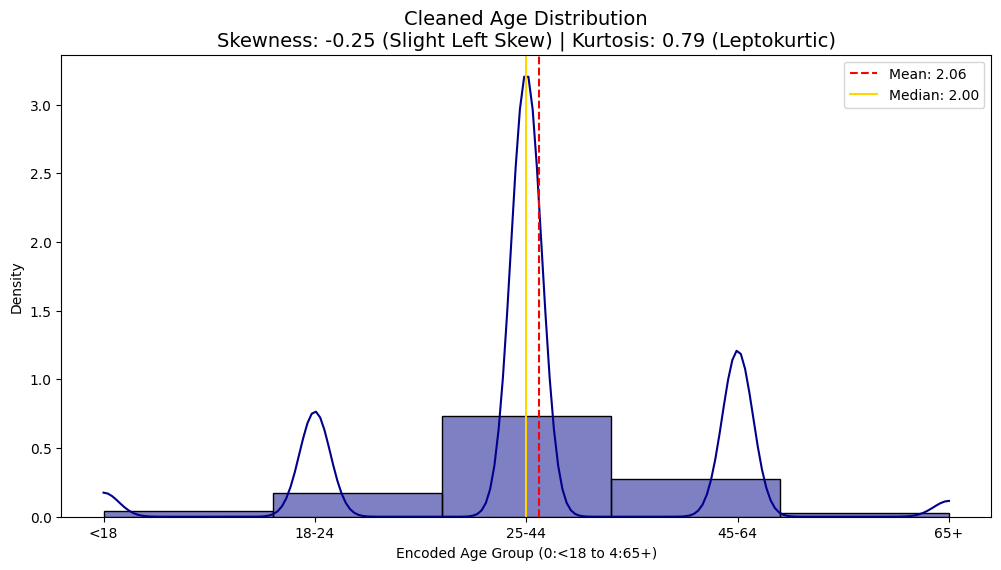

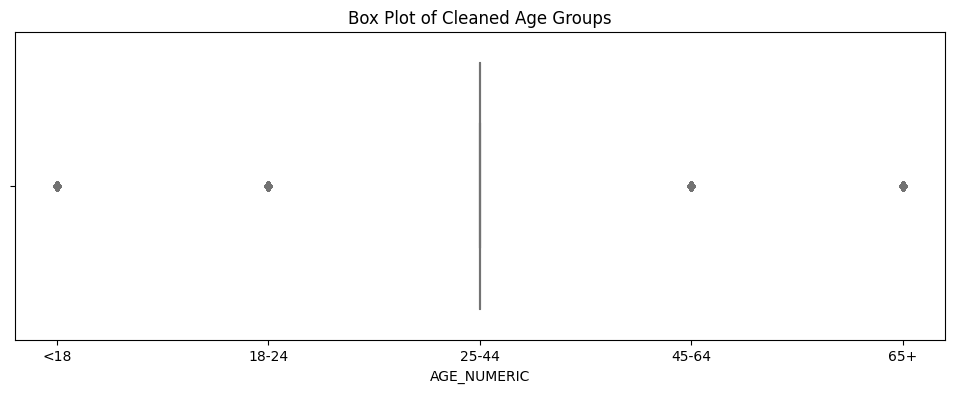

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, kurtosis

# calculate the final stats for the plot labels
final_skew = skew(clean_age_df['AGE_NUMERIC'])
final_kurt = kurtosis(clean_age_df['AGE_NUMERIC'])
mean_val = clean_age_df['AGE_NUMERIC'].mean()
median_val = clean_age_df['AGE_NUMERIC'].median()

# create Histogram with Density Curve
plt.figure(figsize=(12, 6))
sns.histplot(clean_age_df['AGE_NUMERIC'], kde=True, bins=5, color='darkblue', stat="density", alpha=0.5)

# add mean and median lines
plt.axvline(mean_val, color='red', linestyle='--', label=f'Mean: {mean_val:.2f}')
plt.axvline(median_val, color='gold', linestyle='-', label=f'Median: {median_val:.2f}')

# Styling and labels
plt.title(f'Cleaned Age Distribution\nSkewness: {final_skew:.2f} (Slight Left Skew) | Kurtosis: {final_kurt:.2f} (Leptokurtic)', fontsize=14)
plt.xlabel('Encoded Age Group (0:<18 to 4:65+)')
plt.ylabel('Density')
plt.xticks(ticks=[0, 1, 2, 3, 4], labels=['<18', '18-24', '25-44', '45-64', '65+'])
plt.legend()
plt.show()

# Box plot
plt.figure(figsize=(12, 4))
sns.boxplot(x=clean_age_df['AGE_NUMERIC'], color='lightgreen')
plt.title('Box Plot of Cleaned Age Groups')
plt.xticks(ticks=[0, 1, 2, 3, 4], labels=['<18', '18-24', '25-44', '45-64', '65+'])
plt.show()

Obviously this is completely different than our previous plot for age skewness/kurtosis. I think if I'm going to check based on ages I will use the cleaned dataset and if I want to just plot with buroughs I would use the full dataset, so as not to lose valuable information, especially given that the percentages of missing data across the buroughs is so high.

This boxplot is very collapsed. Since we see only a line at the 25-44 group this means that both the 25th percentile, the 50th percentile (median) and the 75th percentile are all the same value (or near) as we can see in the first graph. 
This proves taht more than 50% of the entire dataset falls into a single category. If I ran a frequency test at $\alpha=0.05$ this category would be the statistically dominant mode. The sample size is still large enough to say this isn't a fluke.

Since there's not much to see with the boxplot a violin plot will be a better choice to view the data across the different groups. 

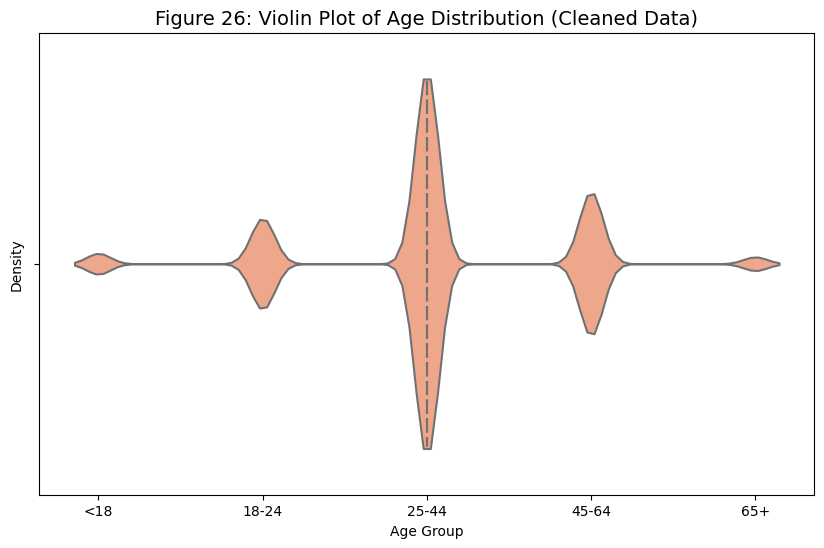

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

# A Violin plot to show the density (KDE) for each category
sns.violinplot(x=clean_age_df['AGE_NUMERIC'], color='lightsalmon', inner='quartile')

plt.xticks(ticks=[0, 1, 2, 3, 4], labels=['<18', '18-24', '25-44', '45-64', '65+'])
plt.title('Figure 26: Violin Plot of Age Distribution (Cleaned Data)', fontsize=14)
plt.xlabel('Age Group')
plt.ylabel('Density')
plt.show()

Here we can see the median line in the 25-44 age group. We can clearly see the very small arrests in the under 18 and over 65 age categories as outliers since they are significantly rarer than the other groups.

I think for the coords we should keep the rows that are 0s, since other data is filled out, and I don't want to lose those records. So we'll replace those with NaN values so our math isn't affected. Coordinates may not be that important since we still have the borough to refer to.

In [13]:
# replace 0 with NaN so they don't affect math, but keep the rows
arrests['X_COORD_CD'] = arrests['X_COORD_CD'].replace(0, np.nan)
arrests['Y_COORD_CD'] = arrests['Y_COORD_CD'].replace(0, np.nan)
arrests.head()

,ARREST_KEY,ARREST_DATE,PD_CD,PD_DESC,KY_CD,OFNS_DESC,LAW_CODE,LAW_CAT_CD,ARREST_BORO,ARREST_PRECINCT,...,PERP_RACE,X_COORD_CD,Y_COORD_CD,Latitude,Longitude,Location,ARREST_MONTH,DAY_OF_WEEK,AGE_GROUP_ENCODED,BORO_NAMED
0,298760433,2025-01-02,782,"WEAPONS, POSSESSION, ETC",236.0,DANGEROUS WEAPONS,PL 2650101,M,Q,115,...,BLACK,NaN,NaN,0.000000,0.000000,POINT (0 0),January,Thursday,-1,Queens
1,299030225,2025-01-07,105,STRANGULATION 1ST,106.0,FELONY ASSAULT,PL 1211200,F,M,28,...,BLACK,997439.0,233857.0,40.808558,-73.952357,POINT (-73.952357 40.808558),January,Tuesday,2,Manhattan
2,299127494,2025-01-08,849,"NY STATE LAWS,UNCLASSIFIED VIO",677.0,OTHER STATE LAWS,LOC00000V0,V,K,81,...,WHITE,NaN,NaN,0.000000,0.000000,POINT (0 0),January,Wednesday,-1,Brooklyn
3,299188536,2025-01-09,259,"CRIMINAL MISCHIEF,UNCLASSIFIED 4",351.0,CRIMINAL MISCHIEF & RELATED OF,PL 1450001,M,M,7,...,BLACK,NaN,NaN,0.000000,0.000000,POINT (0 0),January,Thursday,-1,Manhattan
4,299533742,2025-01-16,155,RAPE 2,104.0,RAPE,PL 1303001,F,K,81,...,BLACK,1005319.0,190473.0,40.689464,-73.924029,POINT (-73.9240290899499 40.6894642952604),January,Thursday,1,Brooklyn


***Data transformation***
I would need to scale the coordinates to use them for K-Means Clustering or K-Nearest Neighbors if I decide to, because they both rely on distance calculations. I don't know what having so many 0s will do yet for the clustering/nearest neighbor so I may have to make some other decisions later on. 

I will continue with data transformation here just for trying it out and for later algorithm use trials. 

In [14]:
from sklearn.preprocessing import StandardScaler

# initialize the StandardScaler
scaler = StandardScaler()

# fit and transform x and y coords - select both columns and apply the scaling
arrests[['X_COORD_CD', 'Y_COORD_CD']] = scaler.fit_transform(arrests[['X_COORD_CD', 'Y_COORD_CD']])

# verify the transform
print("New Mean (should be ~0):", arrests['X_COORD_CD'].mean())
print("New Std Dev (should be 1):", arrests['X_COORD_CD'].std())

# view the scaled coordinates
arrests[['X_COORD_CD', 'Y_COORD_CD']].head()

New Mean (should be ~0): 7.411685668173604e-16
New Std Dev (should be 1): 1.0000023578871915


,X_COORD_CD,Y_COORD_CD
0,NaN,NaN
1,-0.373995,0.880338
2,NaN,NaN
3,NaN,NaN
4,-0.004277,-0.570573


In [15]:
from sklearn.preprocessing import StandardScaler

# initialize the StandardScaler
scaler = StandardScaler()

# fit and transform x and y coords - select both columns and apply the scaling
arrests[['X_COORD_CD', 'Y_COORD_CD']] = scaler.fit_transform(arrests[['X_COORD_CD', 'Y_COORD_CD']])

# verify the transform
print("New Mean (should be ~0):", arrests['X_COORD_CD'].mean())
print("New Std Dev (should be 1):", arrests['X_COORD_CD'].std())

# view the scaled coordinates
arrests[['X_COORD_CD', 'Y_COORD_CD']].head()

New Mean (should be ~0): -4.925598649253011e-18
New Std Dev (should be 1): 1.0000023578871915


,X_COORD_CD,Y_COORD_CD
0,NaN,NaN
1,-0.373995,0.880338
2,NaN,NaN
3,NaN,NaN
4,-0.004277,-0.570573


I should have filled all missing values at this point.

I will just go ahead and replace any nulls that are left with -1 so I could filter it later. 


In [16]:
# Replace "(null)" everywhere with -1
arrests = arrests.replace('(null)', -1)
arrests.head()

,ARREST_KEY,ARREST_DATE,PD_CD,PD_DESC,KY_CD,OFNS_DESC,LAW_CODE,LAW_CAT_CD,ARREST_BORO,ARREST_PRECINCT,...,PERP_RACE,X_COORD_CD,Y_COORD_CD,Latitude,Longitude,Location,ARREST_MONTH,DAY_OF_WEEK,AGE_GROUP_ENCODED,BORO_NAMED
0,298760433,2025-01-02,782,"WEAPONS, POSSESSION, ETC",236.0,DANGEROUS WEAPONS,PL 2650101,M,Q,115,...,BLACK,NaN,NaN,0.000000,0.000000,POINT (0 0),January,Thursday,-1,Queens
1,299030225,2025-01-07,105,STRANGULATION 1ST,106.0,FELONY ASSAULT,PL 1211200,F,M,28,...,BLACK,-0.373995,0.880338,40.808558,-73.952357,POINT (-73.952357 40.808558),January,Tuesday,2,Manhattan
2,299127494,2025-01-08,849,"NY STATE LAWS,UNCLASSIFIED VIO",677.0,OTHER STATE LAWS,LOC00000V0,V,K,81,...,WHITE,NaN,NaN,0.000000,0.000000,POINT (0 0),January,Wednesday,-1,Brooklyn
3,299188536,2025-01-09,259,"CRIMINAL MISCHIEF,UNCLASSIFIED 4",351.0,CRIMINAL MISCHIEF & RELATED OF,PL 1450001,M,M,7,...,BLACK,NaN,NaN,0.000000,0.000000,POINT (0 0),January,Thursday,-1,Manhattan
4,299533742,2025-01-16,155,RAPE 2,104.0,RAPE,PL 1303001,F,K,81,...,BLACK,-0.004277,-0.570573,40.689464,-73.924029,POINT (-73.9240290899499 40.6894642952604),January,Thursday,1,Brooklyn


## Exploratory Data Analysis (EDA) Tasks

First I will start with variable characterists with summary statistics

In [17]:
print(arrests.describe())

         ARREST_KEY          PD_CD          KY_CD  ARREST_PRECINCT  \
count  2.124860e+05  212486.000000  212470.000000    212486.000000   
mean   3.062481e+08     444.569901     258.236942        63.077426   
std    4.357060e+06     273.845791     146.873614        34.890970   
min    2.987043e+08      12.000000     101.000000         1.000000   
25%    3.022993e+08     157.000000     117.000000        40.000000   
50%    3.063403e+08     439.000000     341.000000        62.000000   
75%    3.099783e+08     724.000000     344.000000       100.000000   
max    3.137501e+08     972.000000     995.000000       123.000000   

       JURISDICTION_CODE    X_COORD_CD    Y_COORD_CD       Latitude  \
count      212486.000000  2.120550e+05  2.120550e+05  212486.000000   
mean            0.908479 -4.925599e-18  3.010647e-17      40.653639   
std             6.723647  1.000002e+00  1.000002e+00       1.834632   
min             0.000000 -4.717579e+01 -6.939310e+00       0.000000   
25%           

Let's try this again and add in the objects

In [18]:
# For categorical columns (Boro, Race, Age)
print(arrests.describe(include=['object']))

          PD_DESC                     OFNS_DESC    LAW_CODE LAW_CAT_CD  \
count      212486                        212486      212486     211482   
unique        257                            61        1081          5   
top     ASSAULT 3  ASSAULT 3 & RELATED OFFENSES  PL 1200001          M   
freq        22272                         30096       21839     122788   

       ARREST_BORO AGE_GROUP PERP_SEX PERP_RACE                     Location  \
count       212486    120608   212486    212486                       212486   
unique           5         5        3         7                        38910   
top              K     25-44        M     BLACK  POINT (-73.88151 40.671413)   
freq         60122     70897    99387    102054                         1321   

       ARREST_MONTH DAY_OF_WEEK BORO_NAMED  
count        212486      212486     212486  
unique            9           7          5  
top           April   Wednesday   Brooklyn  
freq          24793       37268      60122  


Here we see our top burro for arrests is Brooklyn, on Wednesdays! April was the biggest month of arrests. The 25-44 age group was the biggest offender and the peretrator's sex was Male and race was black. Top arrests were made for assault 3 offenses.

Checking for skewness of our coordinates to see if they are clustered or spread out

In [19]:
print(f"Skewness: {arrests['X_COORD_CD'].skew()}")
# A value > 1 or < -1 indicates high skewness

Skewness: -0.6368511900911655


This indicates extremely high skewness. This may be because we have so many 0s in our coordinate data. If I decide to do any Machine Learning this will definitely break any algorithms I attempt to use so I'll have to remove all of these.
Let's do some quick checks.

In [20]:
# Compare the median to the mean
print(f"Median: {arrests['X_COORD_CD'].median()}")
print(f"Mean:   {arrests['X_COORD_CD'].mean()}")

# Look at the smallest values in the dataset
print(arrests['X_COORD_CD'].nsmallest(10))

Median: -0.008218349387471183
Mean:   -4.925598649253011e-18
156252   -47.175787
1143      -4.286859
139628    -4.286859
33771     -4.278836
165028    -4.276021
209992    -4.265558
6393      -4.251154
9265      -4.251154
25278     -4.251154
27473     -4.251154
Name: X_COORD_CD, dtype: float64


We will try doing the IQR to help identify which rows are causing this massive skewness in our coordinates.
This will provide us with precision to catch more than just 0s, but also values that are 'too far' from the rest of New York City.

In [21]:
# Calculate Q1 (25th percentile) and Q3 (75th percentile)
Q1 = arrests['X_COORD_CD'].quantile(0.25)
Q3 = arrests['X_COORD_CD'].quantile(0.75)

# Calculate the Interquartile Range
IQR = Q3 - Q1

# Define bounds (standard multiplier is 1.5)
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify any outliers
outliers = arrests[(arrests['X_COORD_CD'] < lower_bound) | (arrests['X_COORD_CD'] > upper_bound)]

print(f"Lower Bound: {lower_bound}")
print(f"Number of Outliers detected: {len(outliers)}")
print(f"Percentage of data that are outliers: {len(outliers)/len(arrests)*100:.2f}%")

Lower Bound: -2.593171041927022
Number of Outliers detected: 5060
Percentage of data that are outliers: 2.38%


I am trying to decide right now how important the coordinates are to the rest of this analysis. I also have the information for which precinct so I could just use that for my analysis. I am concerned I am going down a rabbit hole with trying to figure out coordinates and looking up other ways to transform or what else I could do with them.

## Univariate Analysis

### Categorical Univariate Analysis
Things we will be looking for as we conduct univariate analysis of or NYPD Arrest Data.

- Distribution: how the values are spread out
- Central Tendency: measuring the data using range, variance, and standard deviation
- Frequency: counting how often each category appears

I will start with analysis on some categorical variables


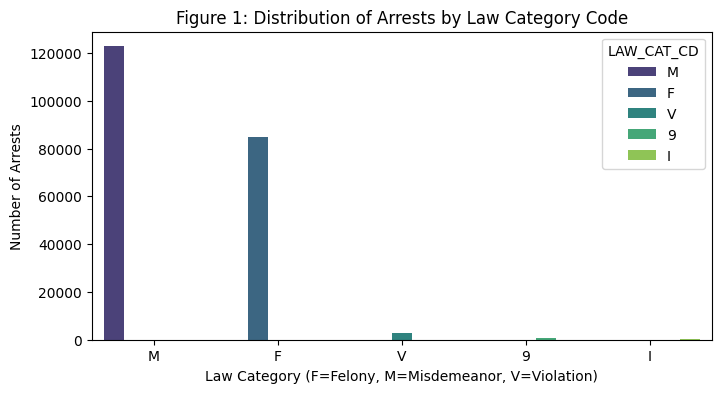

In [31]:
# Distribution of Arrests by the type of law broken
import matplotlib.pyplot as plt
import seaborn as sns

# Percentage distribution
boro_percent = arrests['LAW_CAT_CD'].value_counts(normalize=True) * 100

# Creating a bar chart
plt.figure(figsize=(8,4))
sns.countplot(
    data=arrests, 
    x='LAW_CAT_CD', 
    hue='LAW_CAT_CD', 
    palette='viridis'
)

plt.title('Figure 1: Distribution of Arrests by Law Category Code')
plt.xlabel('Law Category (F=Felony, M=Misdemeanor, V=Violation)')
plt.ylabel('Number of Arrests')
plt.show()

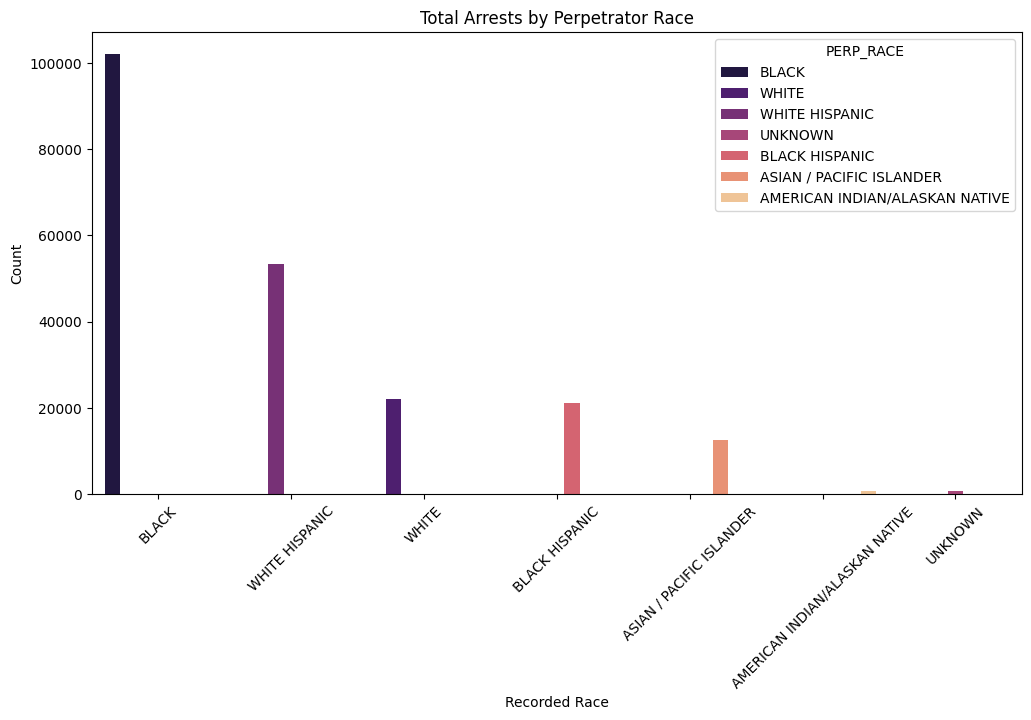

In [32]:
# Arrests by Perpetrator Race
plt.figure(figsize=(12, 6))
sns.countplot(
    data=arrests, 
    x='PERP_RACE', 
    hue='PERP_RACE', 
    palette='magma', 
    order=arrests['PERP_RACE'].value_counts().index
)
plt.title('Total Arrests by Perpetrator Race')
plt.xticks(rotation=45)
plt.xlabel('Recorded Race')
plt.ylabel('Count')
plt.show()

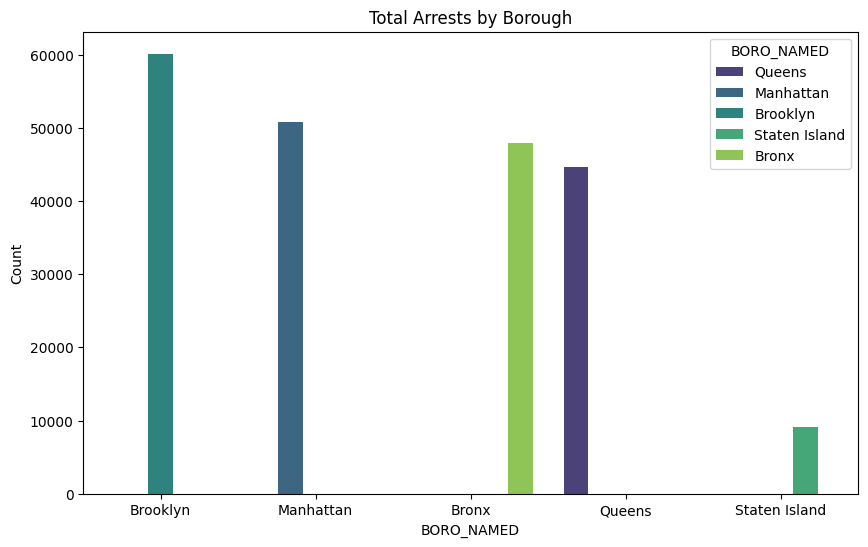

In [33]:
# Arrests by Borough
plt.figure(figsize=(10, 6))
sns.countplot(
    data=arrests, 
    x='BORO_NAMED', 
    hue='BORO_NAMED', 
    palette='viridis', 
    order=arrests['BORO_NAMED'].value_counts().index
)
plt.title('Total Arrests by Borough')
plt.ylabel('Count')
plt.show()

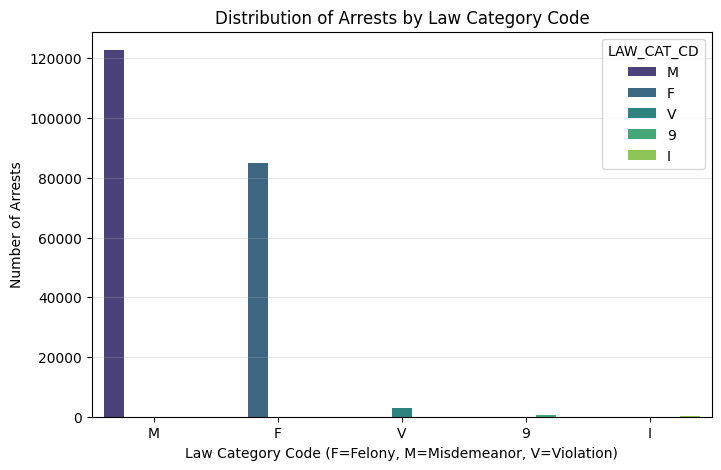

In [86]:
# Distribution of Arrests by the type of law broken
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))

# By setting legend=False and using a high width value, we get fat bars safely
sns.countplot(
    data=arrests, 
    x='LAW_CAT_CD', 
    hue='LAW_CAT_CD',
    palette='viridis',
)

plt.title('Distribution of Arrests by Law Category Code')
plt.xlabel('Law Category Code (F=Felony, M=Misdemeanor, V=Violation)')
plt.ylabel('Number of Arrests')
plt.grid(axis='y', alpha=0.3)
plt.show()

### Numerical Univariate Analysis

We will start with a Histogram with KDE to see a distribution view of the data.
The Kernel Density Estimation (KDE) smooths out the bars to show us the flow of the data.
The KDE Line represents the probability density function of our dataset. This helps us to identify the $\beta B$ distribution characteristics. We can easily notice the right skew with the peak at the younger ages and then tapers off as the age groups increase.

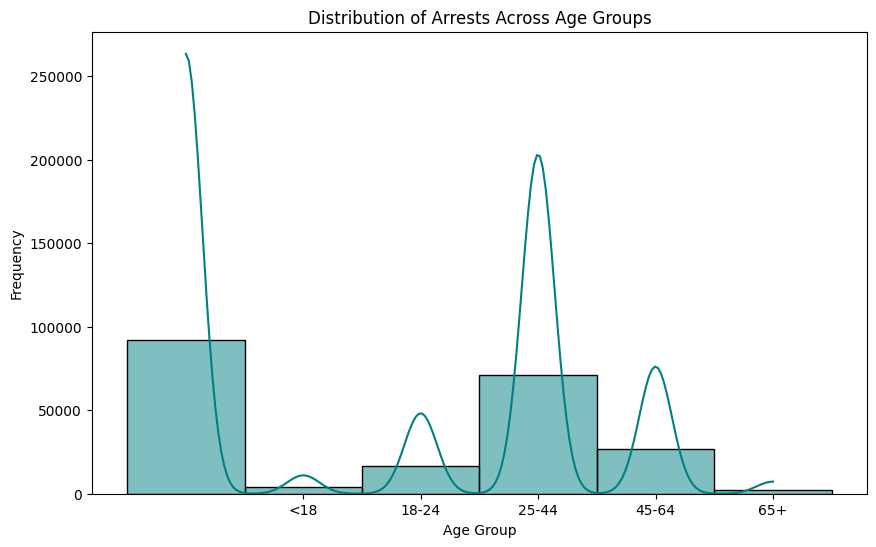

In [36]:
plt.figure(figsize=(10, 6))

# Histogram shows the count, KDE shows the density curve
sns.histplot(data=arrests, x='AGE_GROUP_ENCODED', kde=True, discrete=True, color='teal')

# Add labels for clarity since the axis is encoded
plt.xticks(ticks=[0, 1, 2, 3, 4], labels=['<18', '18-24', '25-44', '45-64', '65+'])

plt.title('Distribution of Arrests Across Age Groups')
plt.xlabel('Age Group')
plt.ylabel('Frequency')
plt.show()

I will do the plot again using the cleaned dataset, with the empty ages filtered out. We can see that large spike there on the left for those empty values.

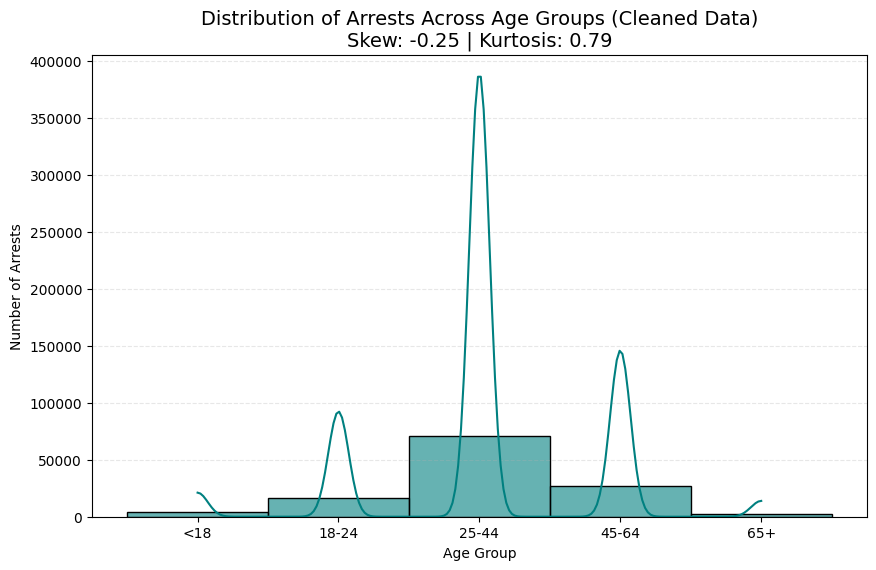

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

# data=clean_age_df and x='AGE_NUMERIC'
# We use discrete=True because these represent distinct age categories
sns.histplot(data=clean_age_df, x='AGE_NUMERIC', kde=True, discrete=True, color='teal', alpha=0.6)

# Map the numeric ticks back to the original labels for the report
plt.xticks(ticks=[0, 1, 2, 3, 4], labels=['<18', '18-24', '25-44', '45-64', '65+'])

# Add descriptive titles incorporating your calculated stats
plt.title('Distribution of Arrests Across Age Groups (Cleaned Data)\nSkew: -0.25 | Kurtosis: 0.79', fontsize=14)
plt.xlabel('Age Group')
plt.ylabel('Number of Arrests')

plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.show()

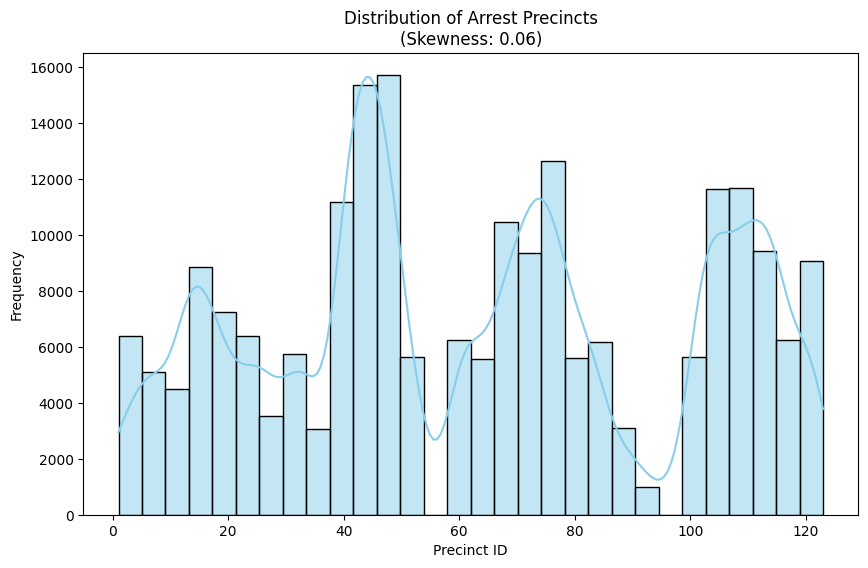

In [38]:
# Histogram and Density Plot
plt.figure(figsize=(10, 6))
sns.histplot(arrests['ARREST_PRECINCT'], kde=True, color='skyblue', bins=30)

# labeling
plt.title(f'Distribution of Arrest Precincts\n(Skewness: {arrests["ARREST_PRECINCT"].skew():.2f})')
plt.xlabel('Precinct ID')
plt.ylabel('Frequency')
plt.show()

Now I'll check which age group has the most arrests in a Boxplot view to give us a more summarized view of the data. The boxplot will highlight our median age group. We want to include our age group labels to make it easier to read.

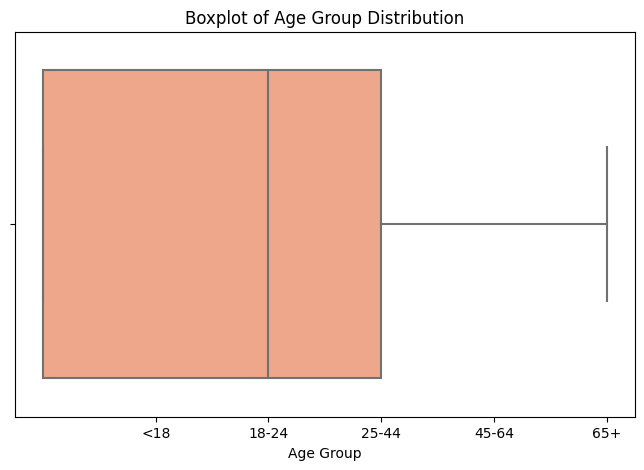

In [39]:
plt.figure(figsize=(8, 5))

# A boxplot visually represents the Median and Interquartile Range (IQR)
sns.boxplot(x=arrests['AGE_GROUP_ENCODED'], color='lightsalmon')

plt.xticks(ticks=[0, 1, 2, 3, 4], labels=['<18', '18-24', '25-44', '45-64', '65+'])
plt.title('Boxplot of Age Group Distribution')
plt.xlabel('Age Group')
plt.show()

--- Statistics for ARREST_PRECINCT ---
Mean: 63.08
Median: 62.00
Mode: 14
Variance: 1217.38
Skewness: 0.06
Kurtosis: -1.14



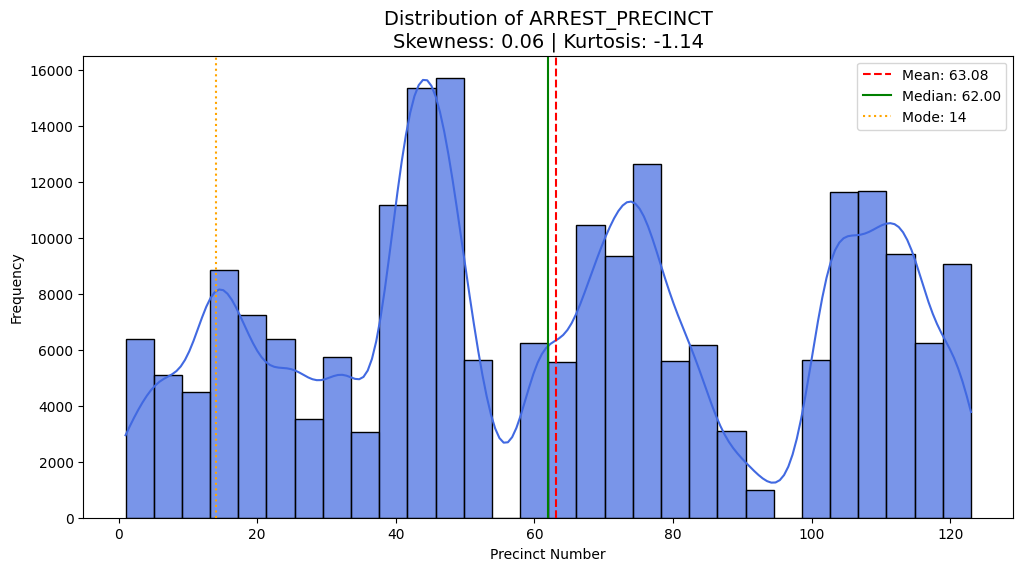

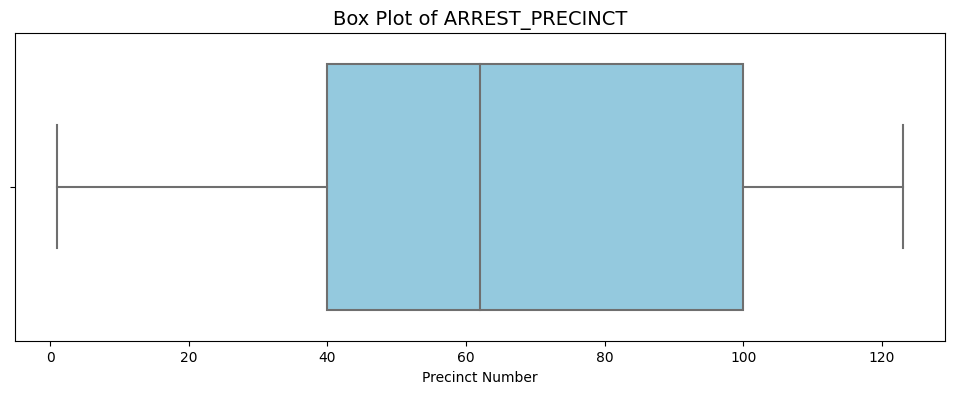

In [40]:
import pandas as pd
from scipy.stats import skew, kurtosis


# Define key variables for analysis
# We'll look at the Arrest Precinct (Numerical) and Borough/Race (Categorical)
num_var = 'ARREST_PRECINCT'
cat_vars = ['BORO_NAMED', 'PERP_RACE', 'AGE_GROUP']

# DESCRIPTIVE STATISTICS

# Calculate stats for the numerical variable
mean_val = arrests[num_var].mean()
median_val = arrests[num_var].median()
mode_val = arrests[num_var].mode()[0]
var_val = arrests[num_var].var()
skew_val = skew(arrests[num_var].dropna())
kurt_val = kurtosis(arrests[num_var].dropna())

print(f"--- Statistics for {num_var} ---")
print(f"Mean: {mean_val:.2f}")
print(f"Median: {median_val:.2f}")
print(f"Mode: {mode_val}")
print(f"Variance: {var_val:.2f}")
print(f"Skewness: {skew_val:.2f}")
print(f"Kurtosis: {kurt_val:.2f}\n")

# histogram and density plot
plt.figure(figsize=(12, 6))

# Histogram with Kernel Density Estimate
sns.histplot(arrests[num_var], kde=True, color='royalblue', bins=30, alpha=0.7)

# Overlay Mean, Median, and Mode
plt.axvline(mean_val, color='red', linestyle='--', label=f'Mean: {mean_val:.2f}')
plt.axvline(median_val, color='green', linestyle='-', label=f'Median: {median_val:.2f}')
plt.axvline(mode_val, color='orange', linestyle=':', label=f'Mode: {mode_val}')

# Formatting
plt.title(f'Distribution of {num_var}\nSkewness: {skew_val:.2f} | Kurtosis: {kurt_val:.2f}', fontsize=14)
plt.xlabel('Precinct Number')
plt.ylabel('Frequency')
plt.legend()
plt.show()

# Box plot for spread and outliers
plt.figure(figsize=(12, 4))
sns.boxplot(x=arrests[num_var], color='skyblue', fliersize=5)

plt.title(f'Box Plot of {num_var}', fontsize=14)
plt.xlabel('Precinct Number')
plt.show()

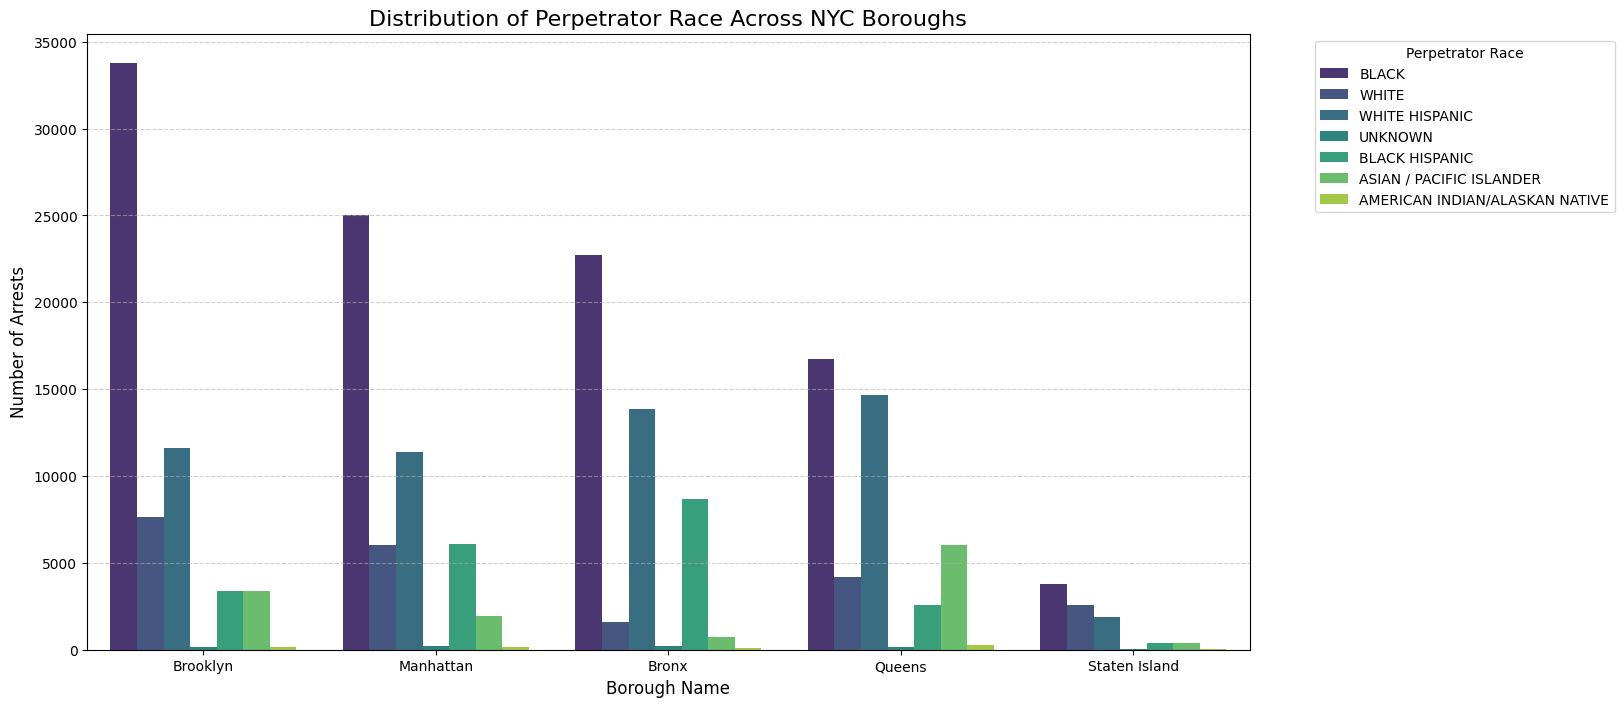

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns

# filtering out '(null)' for a cleaner visual
plot_data = arrests[
    (arrests['PERP_RACE'] != '(null)') & 
    (arrests['BORO_NAMED'] != '(null)')
]

# grouped bar chart
plt.figure(figsize=(15, 8))

sns.countplot(
    data=plot_data, 
    x='BORO_NAMED', 
    hue='PERP_RACE', 
    palette='viridis',
    order=plot_data['BORO_NAMED'].value_counts().index # Sort by busiest Borough
)

# pretty it up
plt.title('Distribution of Perpetrator Race Across NYC Boroughs', fontsize=16)
plt.xlabel('Borough Name', fontsize=12)
plt.ylabel('Number of Arrests', fontsize=12)

# Move legend to the side so it doesn't block the bars
plt.legend(title='Perpetrator Race', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()

## Heatmaps for Univariate Analysis

We'll create a few heatmaps here to check our data for data integrity and missing values. Creating a heatmap is a great way to visualize the 'completeness' of a single variable in our dataset.

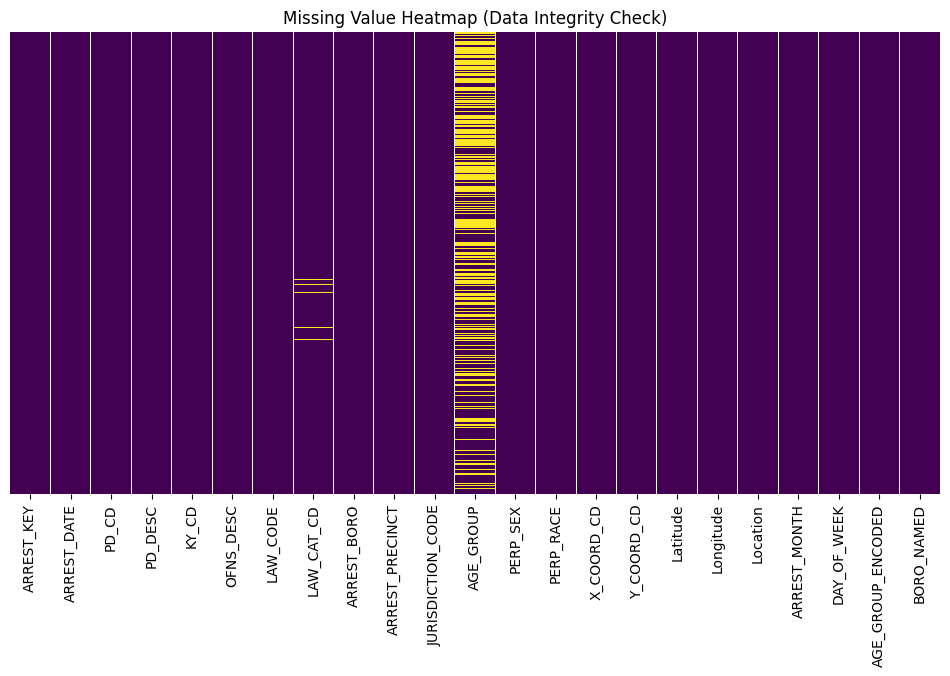

In [42]:
plt.figure(figsize=(12, 6))
sns.heatmap(arrests.isnull(), cbar=False, yticklabels=False, cmap='viridis')
plt.title('Missing Value Heatmap (Data Integrity Check)')
plt.show()

There are so many records missing for AGE_GROUP. That makes me nervous - I definitely don't want to fill in with random things because I think with that many it could cause results that are not reliable. What I need to see is how many records I would delete and if I deleted them how it would impact my analysis moving forward. 
If the data is not distributed evenly across New York then I cannot say that it is Missing Completely At Random (MCAR). 

## Bivariate Analysis

We'll look at the borough vs age group. We want to determine if the age distribution of arrestees is consistent across different locations in NYC.

First we need to create a frequency table that counts age groups per borough.

In [43]:
# Create a cross-tabulation of Borough and Age Group
# We use normalize='index' to see the percentage makeup rather than raw counts
boro_age_dist = pd.crosstab(arrests['BORO_NAMED'], arrests['AGE_GROUP'], normalize='index') * 100

# Reorder columns to ensure age groups flow chronologically
age_order = ['<18', '18-24', '25-44', '45-64', '65+']
boro_age_dist = boro_age_dist[age_order]

print(boro_age_dist)

AGE_GROUP           <18      18-24      25-44      45-64       65+
BORO_NAMED                                                        
Bronx          4.046217  16.091903  58.847227  19.412103  1.602550
Brooklyn       3.593311  13.375758  58.262543  22.634305  2.134083
Manhattan      2.749256  12.161458  57.492560  25.293899  2.302827
Queens         2.601914  14.612007  60.758291  19.907589  2.120199
Staten Island  2.617724  13.439602  57.399825  23.968997  2.573852


Now we can create our stacked bar chart for our visualization

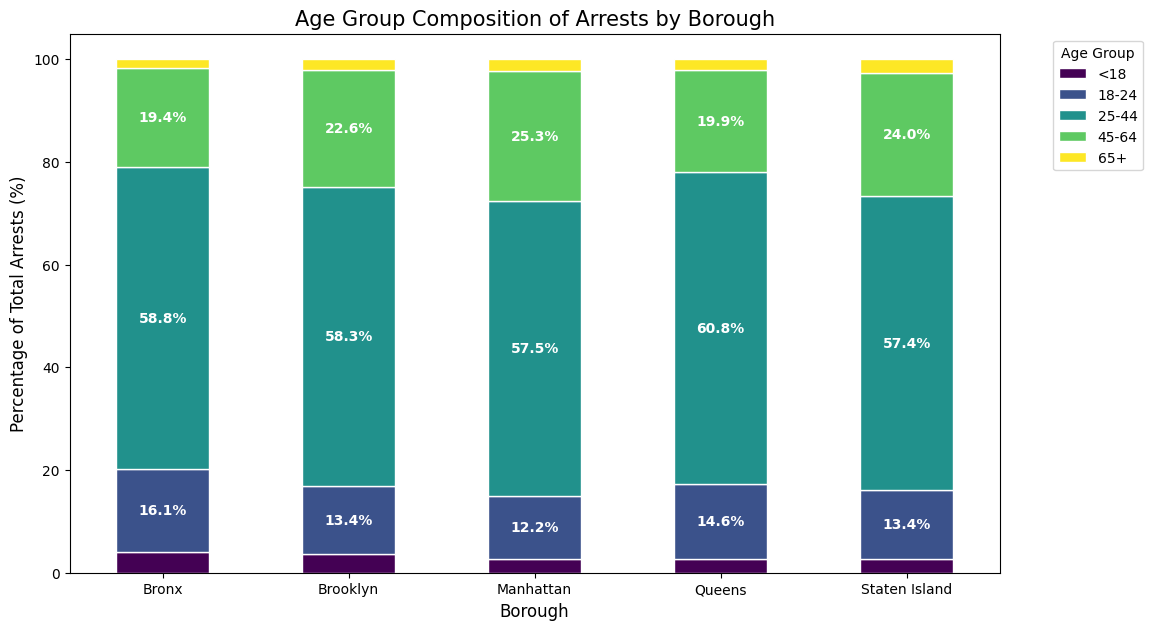

In [44]:
# Plotting
ax = boro_age_dist.plot(kind='bar', 
                        stacked=True, 
                        figsize=(12, 7), 
                        colormap='viridis',
                        edgecolor='white')

plt.title('Age Group Composition of Arrests by Borough', fontsize=15)
plt.xlabel('Borough', fontsize=12)
plt.ylabel('Percentage of Total Arrests (%)', fontsize=12)
plt.legend(title='Age Group', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=0) # Keeps borough names horizontal

# Add percentage labels on the bars for better scannability
for p in ax.patches:
    width, height = p.get_width(), p.get_height()
    if height > 5: # Only show labels for segments larger than 5%
        x, y = p.get_xy() 
        ax.text(x+width/2, 
                y+height/2, 
                f'{height:.1f}%', 
                ha='center', 
                va='center', 
                color='white', 
                fontweight='bold')

plt.show()

This is a great way for us to get a comparison across the different burroughs and since we normalized the data we can compare the proportions of age groups in a more relative comparison. We can clearly see that Manhattan has a higher percentage of 45-64 year old arrests compared to the Bronx. We can also see our >18 group which is our empty values for ages. 

Now let's try a heatmap so we can visualize 'hot spots' where specific crimes are clustered in specific buroughs. My goal here is to visualize the density of different crime types across NYC to identify geographical patterns. We will only look at the top 10 offenses to reduce the risk of failing to find a meaningful pattern because the data is spread too thin across the offense codes.

In [87]:
# since there are dozens of offense types first we will filter for the most frequent ones to allow us read the heatmap

# Identify the Top 10 most frequent offenses
top_offenses = arrests['OFNS_DESC'].value_counts().nlargest(10).index

# Filter the dataframe for only these offenses
arrests_top = arrests[arrests['OFNS_DESC'].isin(top_offenses)]

# Create a pivot table (counts of offenses per borough)
heatmap_data = pd.crosstab(arrests_top['OFNS_DESC'], arrests_top['BORO_NAMED'])

# normalize by column (Borough) to see proportions per borough
heatmap_norm = pd.crosstab(arrests_top['OFNS_DESC'], arrests_top['BORO_NAMED'], normalize='columns') * 100

Now we can create our heatmap

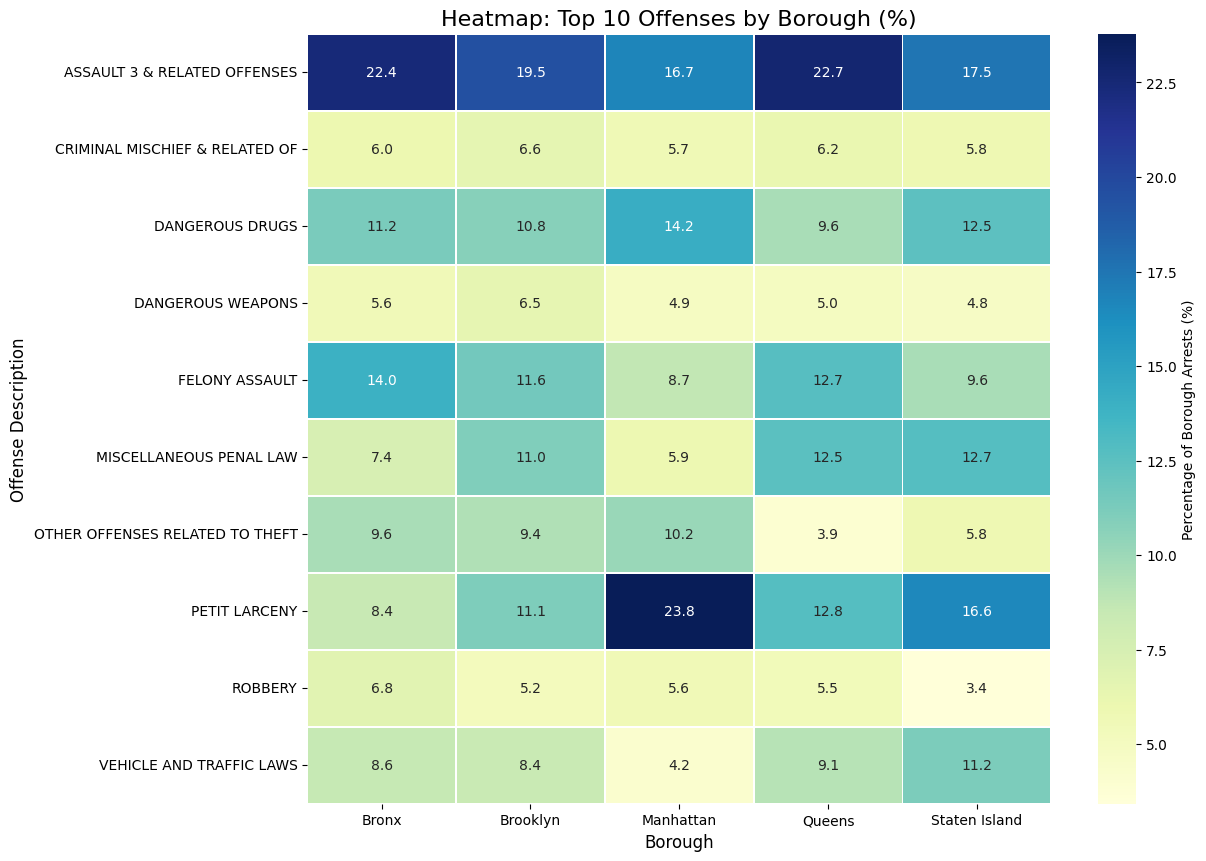

In [47]:
plt.figure(figsize=(12, 10))

# using the 'YlGnBu' color map (Yellow-Green-Blue) for clear contrast
sns.heatmap(heatmap_norm, 
            annot=True, 
            cmap='YlGnBu', 
            fmt=".1f", 
            linewidths=.5,
            cbar_kws={'label': 'Percentage of Borough Arrests (%)'})

plt.title('Heatmap: Top 10 Offenses by Borough (%)', fontsize=16)
plt.xlabel('Borough', fontsize=12)
plt.ylabel('Offense Description', fontsize=12)
plt.show()

The darkest blue shows hot spots  - like petty larceny (Petit Larceny) in Manhattan. This means that petty larceny makes up a significantly higher percentage of Manhattan's arrests compared to the other boroughs. It also allows us to see if the same crime type is evenly distributed across the city or concentrated in one place. We can also easily see the crime profile for a specific borough as we look down the columns. 

This was a great way to see the crime stats for the top crime types per borough.

Now we will calculate descriptive statistics (mean, median, mode, variance, skewness, kurtosis) of the key variables in my dataset.
Python has a great method, `agg()` in Pandas that will summarize the data and calculate mean, sum, or count of a dataset or specific groups inside it. 

In [89]:
# Select the key numerical/encoded columns
key_vars = ['JURISDICTION_CODE', 'ARREST_PRECINCT', 'AGE_GROUP_ENCODED']

# Calculate all requested statistics
stats_summary = clean_age_df[key_vars].agg([
    'mean', 
    'median', 
    'std',      # Standard Deviation
    'var',      # Variance
    'skew',     # Skewness
    'kurt'      # Kurtosis
]).transpose()

# Add the Mode separately (as it can return multiple values)
stats_summary['mode'] = [arrests[col].mode()[0] for col in key_vars]

# Display the formatted table
print("### Descriptive Statistics Summary ###")
print(stats_summary.round(3))

### Descriptive Statistics Summary ###
                     mean  median     std       var   skew    kurt  mode
JURISDICTION_CODE   1.097     0.0   7.730    59.747  9.712  98.887     0
ARREST_PRECINCT    67.260    70.0  35.876  1287.120 -0.107  -1.213    14
AGE_GROUP_ENCODED   2.059     2.0   0.753     0.567 -0.251   0.786    -1


The mean tells us the 'average' for the age group. There aren't a ton of numerical columns in this dataset that mean alot, so the Jurisdiction code and arrest precinct don't really make sesnse this way. 
Median will tell us the middle value. I see the mean and median are quite close, meaning my age data is remarkably symmetrical. the ~2.0 value corresponds to the 25-44 age group, confirming this is the primary focus of NYPD activity.
The slight negative skew of -0.251 means there is a very thing 'tail' of younger arrestees, but the bulk of the data is concentrated toward the adult side. 
The kurtosis of 0.786 indicates a 'peaked' distribution. This is what we observed in the earlier graph visualizations. It proves that arrests aren't spread evenly across all ages. They are heavily clustered around that young-adult 'peak.'
Variance is the fluctuation. It measures how far the numbers are spread out from the average value. This let's me know whether the demographis are tightly packed around a specific profile or scattered across different types of people. For the age, we see that the variance number is low, 0.567, again confirming that the 'age of arrest' is not a wild, unpredictable variable. 


In [90]:
arrests['AGE_GROUP'].value_counts()

25-44    70897
45-64    26545
18-24    16801
<18       3840
65+       2525
Name: AGE_GROUP, dtype: int64

Even though our 25-44 age group is the largest, since the numbers drop off will create a shoulder effect than a spike. We still have a substantial group in the 35-64 age group and the same in the 18-24. 
The 25-44 group is clearly our mode, and most frequent value.
Based on our value counts we expect a positive skew since the data will tail off toward teh older age brackets. 

Skewness of Age Group Encoded: -0.251


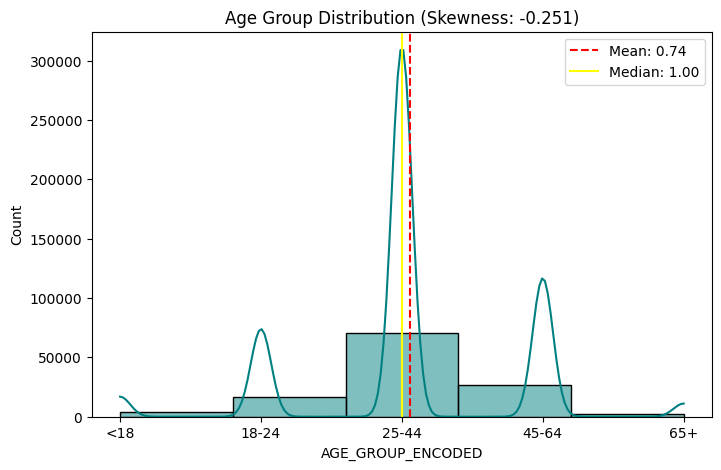

In [88]:
# Calculate the Skewness value
age_skew = clean_age_df['AGE_GROUP_ENCODED'].skew()

print(f"Skewness of Age Group Encoded: {age_skew:.3f}")


plt.figure(figsize=(8, 5))
sns.histplot(clean_age_df['AGE_GROUP_ENCODED'], kde=True, color='teal', bins=5)

# Add a vertical line for the Mean and Median to visualize the skew
plt.axvline(clean_age_df['AGE_GROUP_ENCODED'].mean(), color='red', linestyle='--', label=f'Mean: {arrests["AGE_GROUP_ENCODED"].mean():.2f}')
plt.axvline(clean_age_df['AGE_GROUP_ENCODED'].median(), color='yellow', linestyle='-', label=f'Median: {arrests["AGE_GROUP_ENCODED"].median():.2f}')

plt.title(f'Age Group Distribution (Skewness: {age_skew:.3f})')
plt.xticks(ticks=[0, 1, 2, 3, 4], labels=['<18', '18-24', '25-44', '45-64', '65+'])
plt.legend()
plt.show()

### EDA Task 2: Bivariate Analysis - Correlation Heatmap
Now we will create a correlation heatmap of our precinct, jurisdiction code and lat/lon values.
The goal here is to find a linear relationship between our numerical features

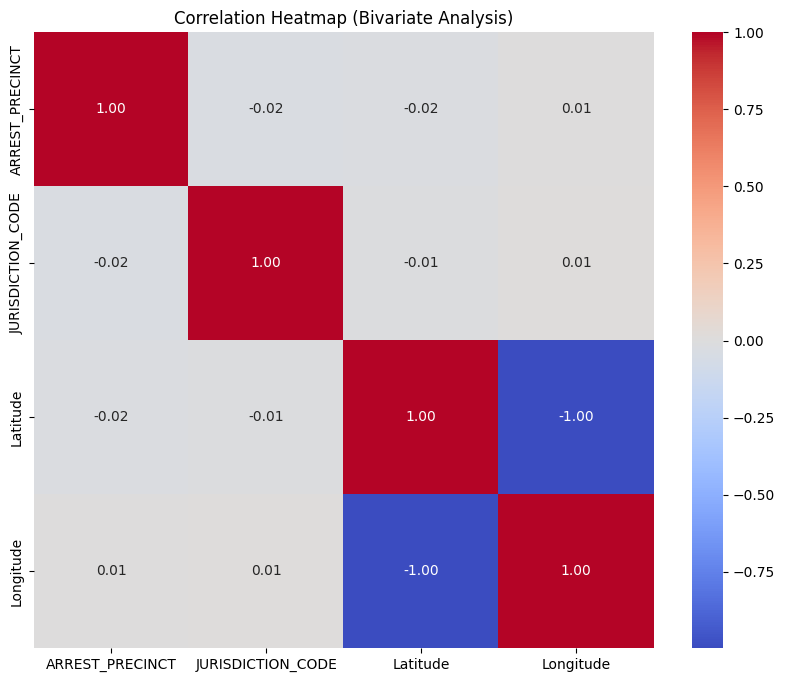

In [53]:
# Select only relevant numerical columns
corr_cols = ['ARREST_PRECINCT', 'JURISDICTION_CODE', 'Latitude', 'Longitude']
plt.figure(figsize=(10, 8))
sns.heatmap(arrests[corr_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap (Bivariate Analysis)')
plt.show()

We can also create a frequency heatmap to visualize the distribution of one variable across the cateogires of another- in our cases we will use the boro the arrest took place in and the age group and then create a frequency heatmap.
The goal here is to identify hotspots or patterns in our categorical data

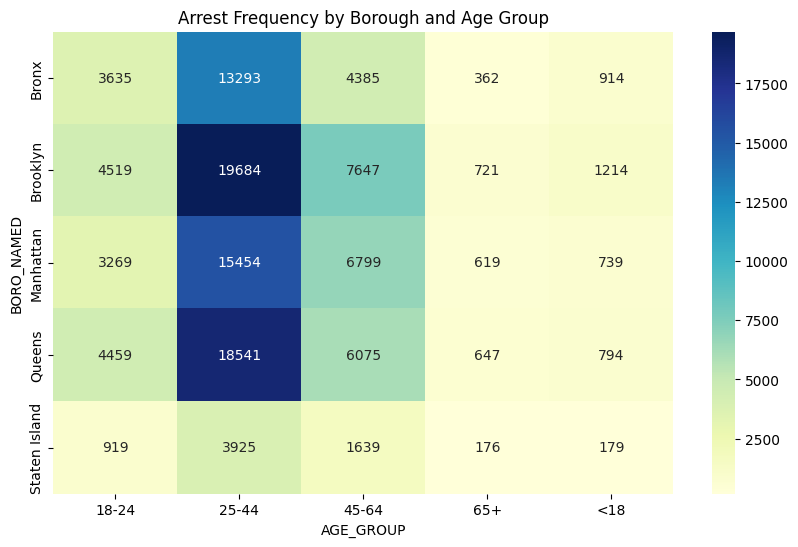

In [13]:
# Creating a pivot table for the heatmap
pivot_table = clean_age_df.groupby(['BORO_NAMED', 'AGE_GROUP']).size().unstack(fill_value=0)

plt.figure(figsize=(10, 6))
sns.heatmap(pivot_table, annot=True, fmt="d", cmap="YlGnBu")
plt.title('Arrest Frequency by Borough and Age Group')
plt.show()

we'll try a regression scatter plot to see the trend of crimes over the timeline of the data we have available. 

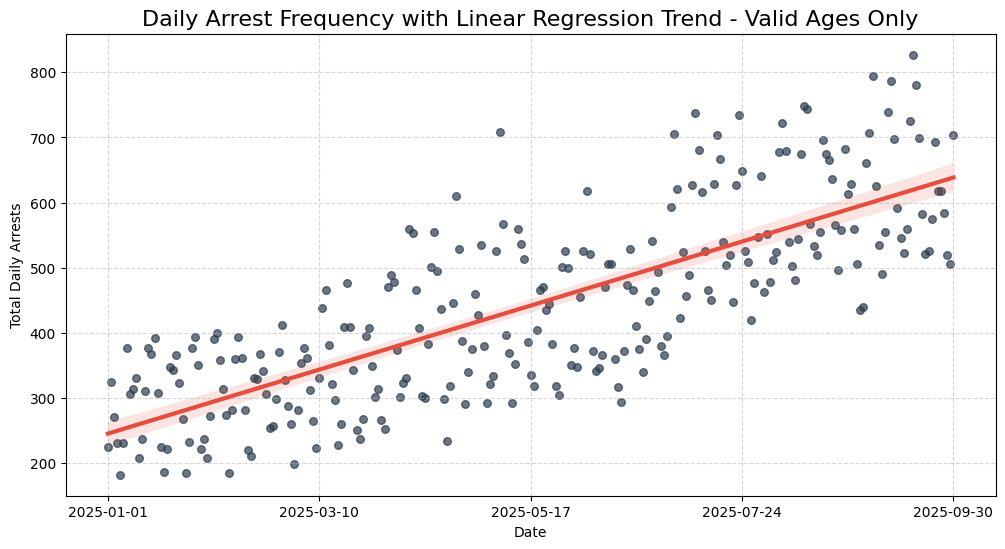

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# first we will group by date and count daily arrests
daily_arrests = clean_age_df.groupby('ARREST_DATE').size().reset_index(name='count')

# now convert dates to a numeric format (days from start) for regression calculation
daily_arrests['date_numeric'] = (daily_arrests['ARREST_DATE'] - daily_arrests['ARREST_DATE'].min()).dt.days

plt.figure(figsize=(12, 6))

# then create the Regression Plot
sns.regplot(
    data=daily_arrests,
    x='date_numeric',
    y='count',
    scatter_kws={'alpha': 0.7, 's': 30, 'color': '#2c3e50'}, # Darker, opaque points
    line_kws={'color': '#e74c3c', 'lw': 3}                  # Bold red trend line
)

# and format the X-axis to show dates instead of numbers
xticks = np.linspace(0, daily_arrests['date_numeric'].max(), 5)
xtick_labels = [daily_arrests['ARREST_DATE'].min() + pd.Timedelta(days=int(d)) for d in xticks]
plt.xticks(xticks, [d.strftime('%Y-%m-%d') for d in xtick_labels])

# title and labels
plt.title('Daily Arrest Frequency with Linear Regression Trend - Valid Ages Only', fontsize=16)
plt.xlabel('Date')
plt.ylabel('Total Daily Arrests')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

If I use my clean dataset crimes actually dramatically increase between the beginning of the year and the end of September.

Doing some research online I see that NYC saw "historic reductions in overall crime through the first quarter of 2025. From: [NYPD Historic Crime Reductions First Quarter 2025 Report](https://www.nyc.gov/site/nypd/news/pr008/nypd-historic-crime-reductions-first-quarter-2025-fewest-shooting-incidents-in#:~:text=New%20York%2C%20New%20York%20%E2%80%93%20Police,6%2C535)

That's not what I see with this cleaned dataset. I'll try again with the full dataset.

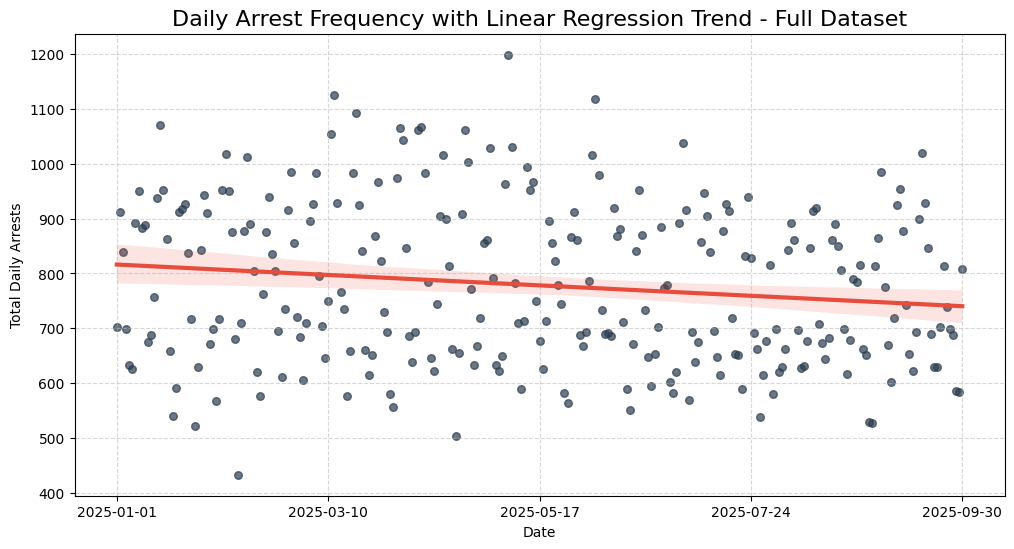

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# first we will group by date and count daily arrests
daily_arrests = arrests.groupby('ARREST_DATE').size().reset_index(name='count')

# now convert dates to a numeric format (days from start) for regression calculation
daily_arrests['date_numeric'] = (daily_arrests['ARREST_DATE'] - daily_arrests['ARREST_DATE'].min()).dt.days

plt.figure(figsize=(12, 6))

# then create the Regression Plot
sns.regplot(
    data=daily_arrests,
    x='date_numeric',
    y='count',
    scatter_kws={'alpha': 0.7, 's': 30, 'color': '#2c3e50'}, # Darker, opaque points
    line_kws={'color': '#e74c3c', 'lw': 3}                  # Bold red trend line
)

# and format the X-axis to show dates instead of numbers
xticks = np.linspace(0, daily_arrests['date_numeric'].max(), 5)
xtick_labels = [daily_arrests['ARREST_DATE'].min() + pd.Timedelta(days=int(d)) for d in xticks]
plt.xticks(xticks, [d.strftime('%Y-%m-%d') for d in xtick_labels])

# title and labels
plt.title('Daily Arrest Frequency with Linear Regression Trend - Full Dataset', fontsize=16)
plt.xlabel('Date')
plt.ylabel('Total Daily Arrests')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

With the full original dataset the line is fairly straight but does have a slightly downward trend, showing crimes have decreased since 1/1/2025 to 9/30/25. Perhaps there were less arrests being made. 

Scatter plot for our arrest locations to visualize the physical density of arrests across New York City

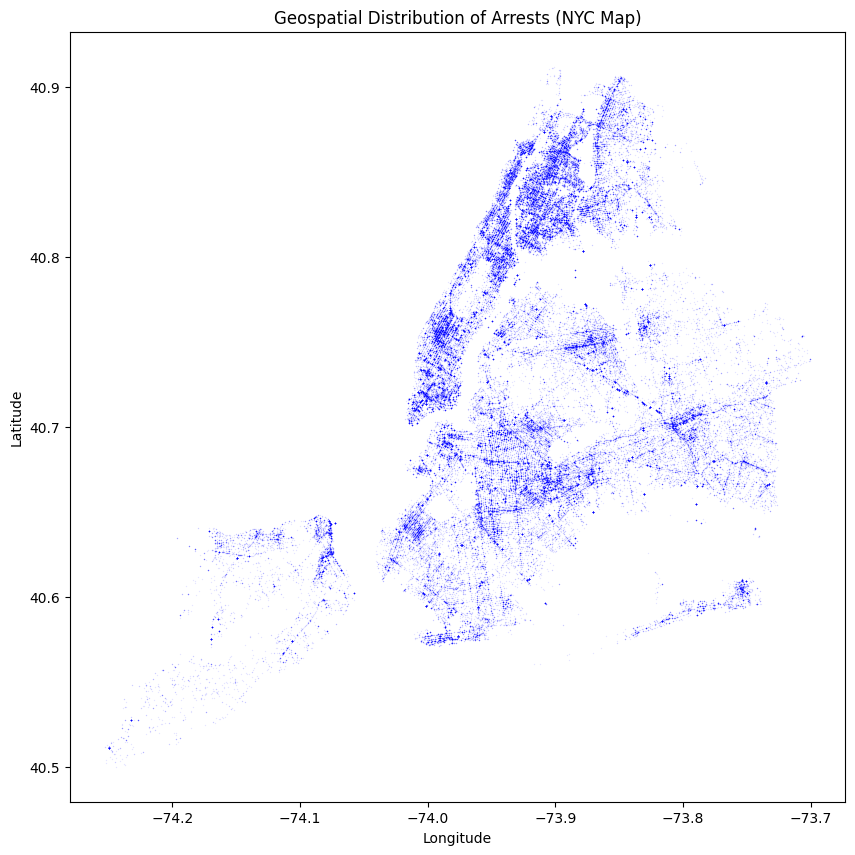

In [56]:
plt.figure(figsize=(10, 10))
sns.scatterplot(
    data=arrests[arrests['Latitude'] != 0], # Filtering out invalid coordinates
    x='Longitude', 
    y='Latitude', 
    alpha=0.1,      
    # High alpha (transparency) helps show density
    s=1,            
    # Small point size for high-volume data
    color='blue'
)
plt.title('Geospatial Distribution of Arrests (NYC Map)')
plt.show()

It is very cool to see the map of NYC with the coords (even though I had some filtered out). It is clear that there is still enough data to get a good view of the city's arrest records. You can even make out streets!

## Multivariate Analysis

We want to examine 3+ variables in our multivariate analysis so we'll take our above bivariate and add into it the arrest boro so we can visually see the different boros across New York City. 

Here we can visualize the different boros

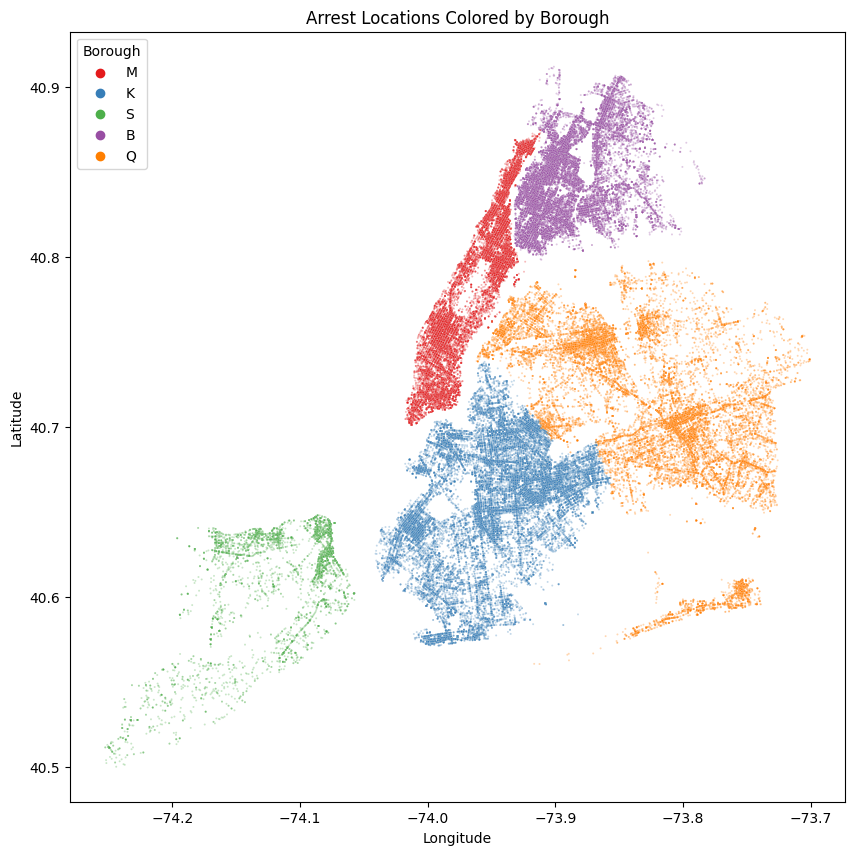

In [57]:
plt.figure(figsize=(10, 10))
sns.scatterplot(
    data=arrests[arrests['Latitude'] != 0], 
    x='Longitude', 
    y='Latitude', 
    hue='ARREST_BORO', # The 3rd variable
    palette='Set1',
    alpha=0.3, 
    s=2
)
plt.title('Arrest Locations Colored by Borough')
plt.legend(title='Borough', loc='upper left')
plt.show()

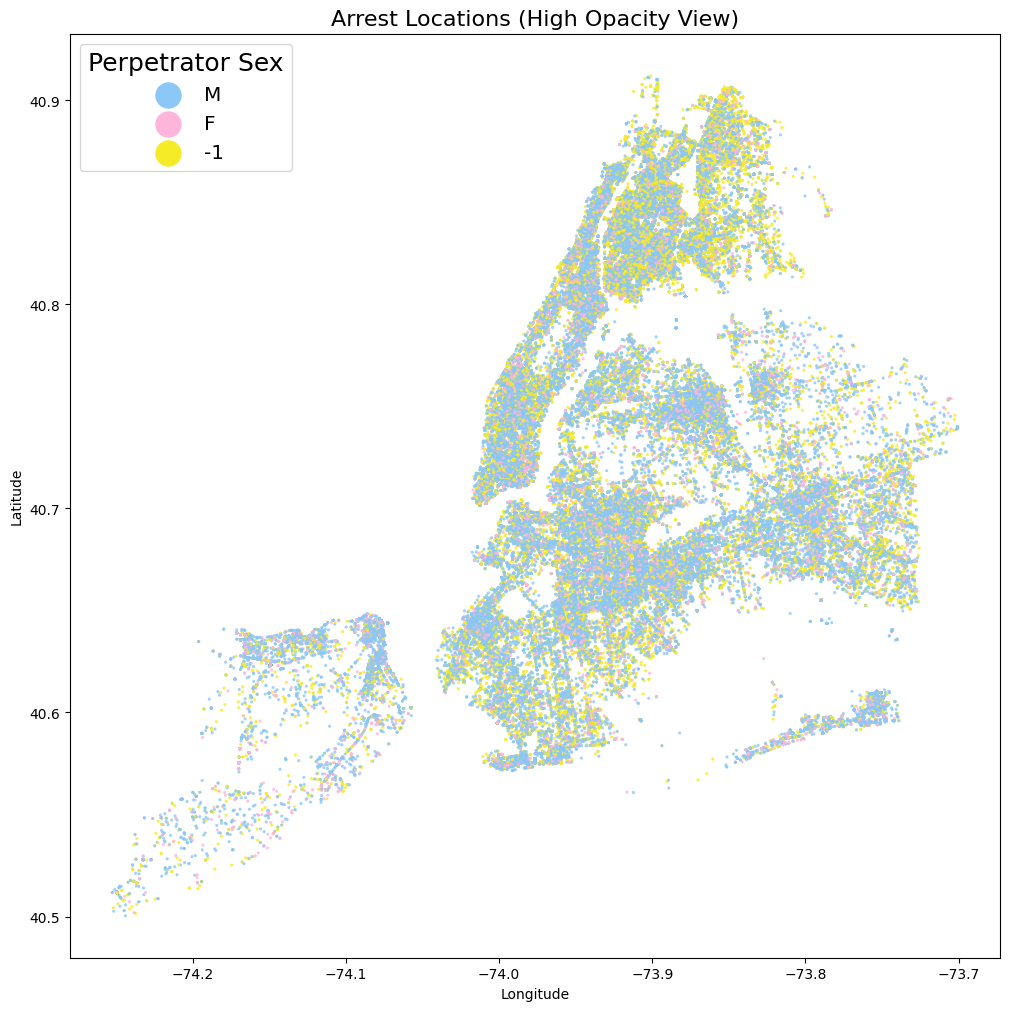

In [91]:
import matplotlib.pyplot as plt
import seaborn as sns

# Data Preparation
plot_data = arrests[(arrests['Latitude'] != 0) & (arrests['PERP_SEX'] != '(null)')]

# Define Custom Palette with Integer Fix
sex_palette = {
    'M': '#8bc7f7', 
    'F': '#feb5da', 
    -1: '#F5EB27'   # Integer key for missing data
}

plt.figure(figsize=(12, 12))

# Multivariate scatter plot
sns.scatterplot(
    data=plot_data,
    x='Longitude',
    y='Latitude',
    hue='PERP_SEX',
    palette=sex_palette,
    alpha=0.8,
    s=5,
    linewidth=0
)

# enhanced legend
plt.legend(
    title='Perpetrator Sex',
    loc='upper left',
    fontsize='x-large',
    title_fontsize='18',
    markerscale=3
)

plt.title('Arrest Locations (High Opacity View)', fontsize=16)
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

This is a clear visualization that crimes in NYC are mostly perpetrated by men. It is also astounding how many unknowns there are (which we captured in our -1 variable).


#### Age Spread by Borough
By comparing the age distributions across boroughs, we can determine if certain areas of New York City have a younger or older arrest profile.


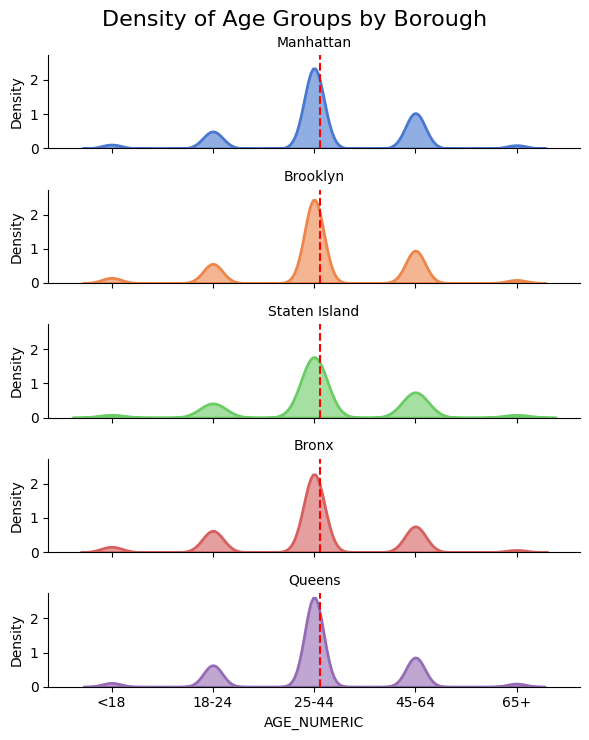

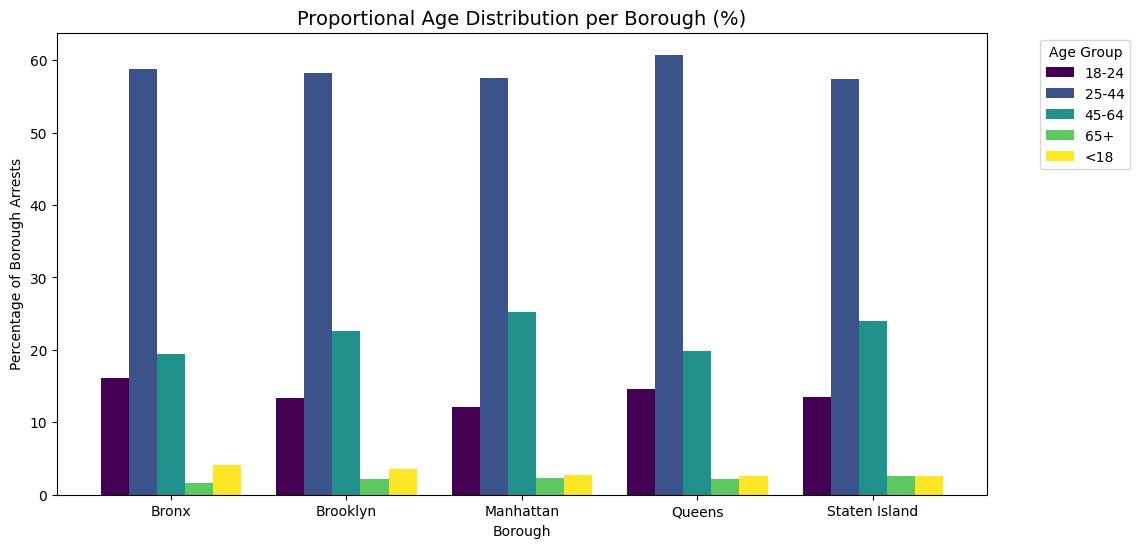

In [59]:
import matplotlib.pyplot as plt
import seaborn as sns

# Identify which column name is currently in your dataframe - I did this because I was having issues
# when I was re-running my kernel that sometimes I didn't go back and run all the cells
# doing the check here so in case I don't have the BORO_NAMED yet I can still create my plots
if 'BORO_NAMED' in clean_age_df.columns:
    boro_col = 'BORO_NAMED'
else:
    boro_col = 'ARREST_BORO'

# Create the Faceted Density Plot
# Note: 'fill=True' to color the area under the curve
g = sns.FacetGrid(clean_age_df, row=boro_col, hue=boro_col, aspect=4, height=1.5, palette='muted')

# Map the density plots
g.map(sns.kdeplot, "AGE_NUMERIC", fill=True, alpha=0.6, lw=2)

# Map a citywide mean line for comparison
city_mean = clean_age_df['AGE_NUMERIC'].mean()
g.map(plt.axvline, x=city_mean, color='red', linestyle='--', label='City Average')

# Formatting the Facets
g.set_titles("{row_name}")
g.set(xticks=[0, 1, 2, 3, 4])
g.set_xticklabels(['<18', '18-24', '25-44', '45-64', '65+'])

plt.subplots_adjust(top=0.92)
g.fig.suptitle('Density of Age Groups by Borough', fontsize=16)

plt.show()

# Do my next plot so I have the age data I need already
# Percentage Distribution Bar Chart
# This shows the proportion of each age group within the borough
age_boro_counts = clean_age_df.groupby([boro_col, 'AGE_GROUP']).size().unstack()
age_boro_props = age_boro_counts.div(age_boro_counts.sum(axis=1), axis=0) * 100

ax = age_boro_props.plot(kind='bar', figsize=(12, 6), colormap='viridis', width=0.8)

plt.title('Proportional Age Distribution per Borough (%)', fontsize=14)
plt.ylabel('Percentage of Borough Arrests')
plt.xlabel('Borough')
plt.legend(title='Age Group', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=0)
plt.show()

It's very clear that the 25-44 age really is the highest for all the burroughs. There seems to be very small variations in the ages, Clearly some Under 18 is a little higher in other places, looks like the Bronx over Staten Island. While the 45-64 looks heighest in Manhattan. the 65+ crime is lowest in the Bronx and appears higher in Staten Island and Brooklyn. 

#### Visualizing my Problem Statement

I want to visualize age/race spread across the boroughs. I'll test this out with a few visualizations.

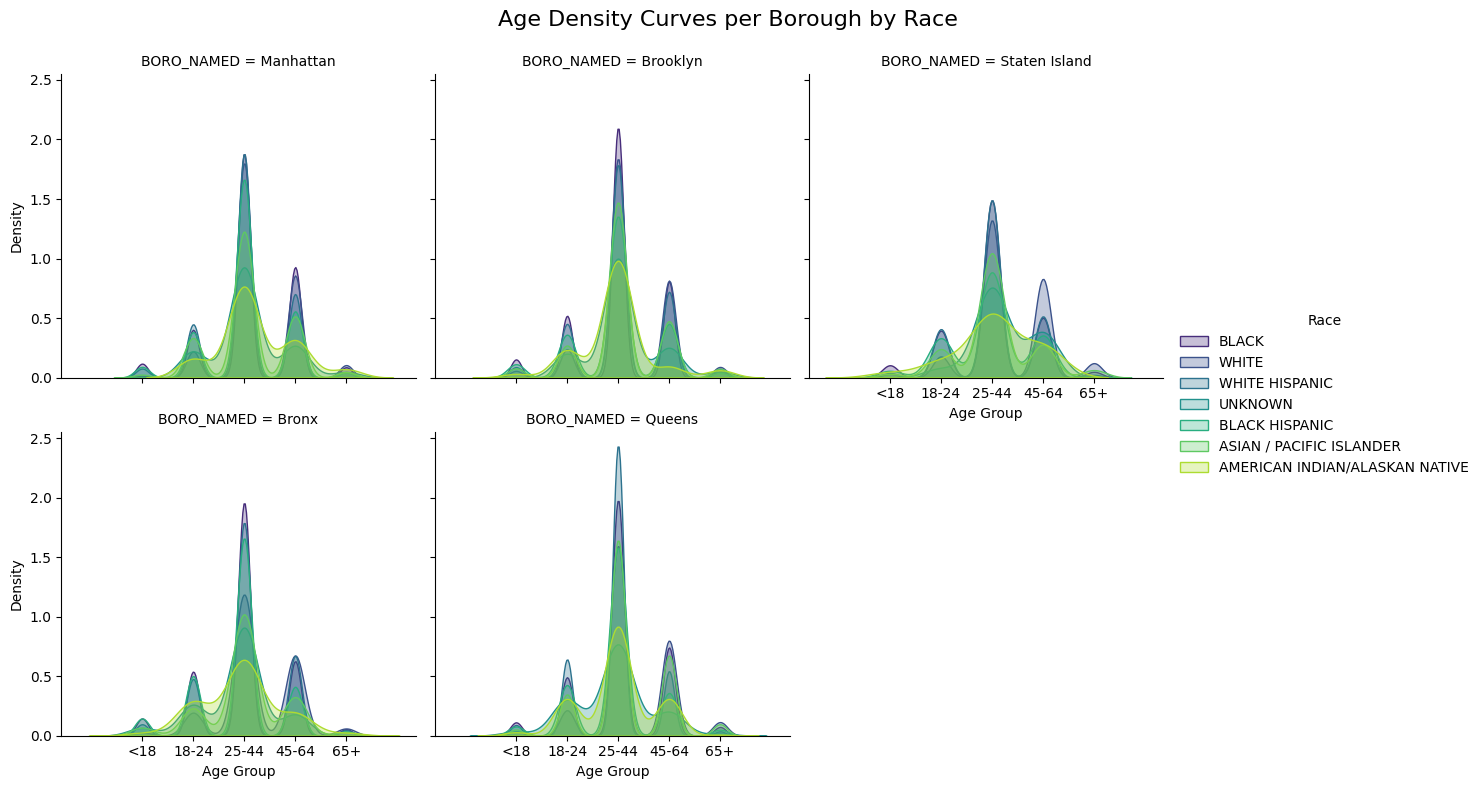

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

# We use FacetGrid to split the view by Borough
g = sns.FacetGrid(clean_age_df, col="BORO_NAMED", hue="PERP_RACE", col_wrap=3, height=4, palette='viridis')

# KDE plot shows the probability density of ages
g.map(sns.kdeplot, "AGE_NUMERIC", fill=True, alpha=0.3)

# Formatting the axes to show real age labels instead of 0-4
g.set(xticks=[0, 1, 2, 3, 4])
g.set_xticklabels(['<18', '18-24', '25-44', '45-64', '65+'])

g.add_legend(title="Race")
g.set_axis_labels("Age Group", "Density")
plt.subplots_adjust(top=0.9)
g.fig.suptitle('Age Density Curves per Borough by Race', fontsize=16)

plt.show()

The peaks of the age density curves are largely aligned across the boroughs.

Now we'll try a heatmap to see the age/race footprint of each borough. This allows me to see the race and density of arrests for each of the boroughs. 

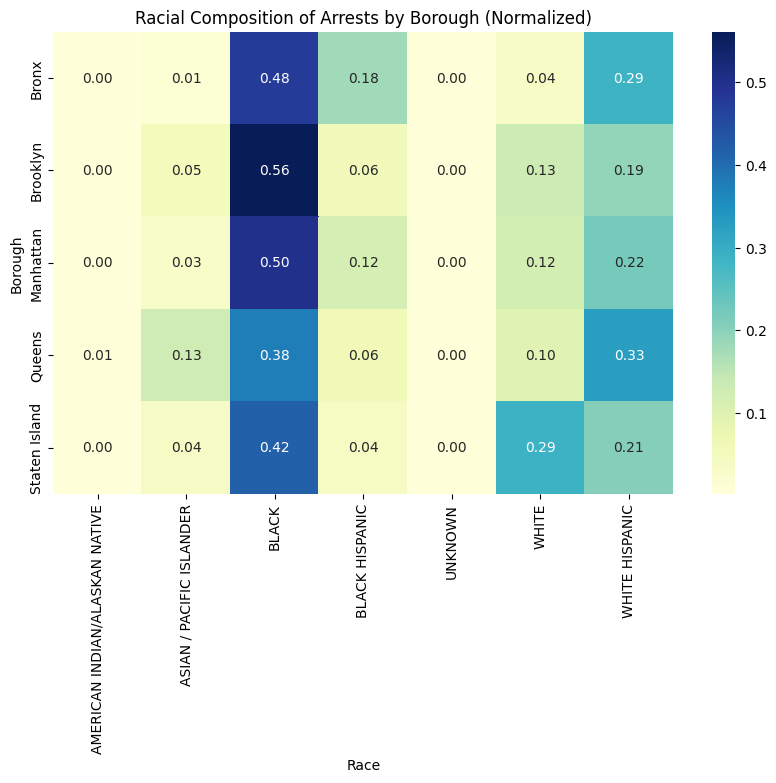

In [24]:
# Create a cross-tabulation of Borough and Race
race_boro_dist = pd.crosstab(clean_age_df['BORO_NAMED'], arrests['PERP_RACE'], normalize='index')

plt.figure(figsize=(10, 6))
sns.heatmap(race_boro_dist, annot=True, cmap='YlGnBu', fmt='.2f')

plt.title('Racial Composition of Arrests by Borough (Normalized)')
plt.xlabel('Race')
plt.ylabel('Borough')
plt.show()

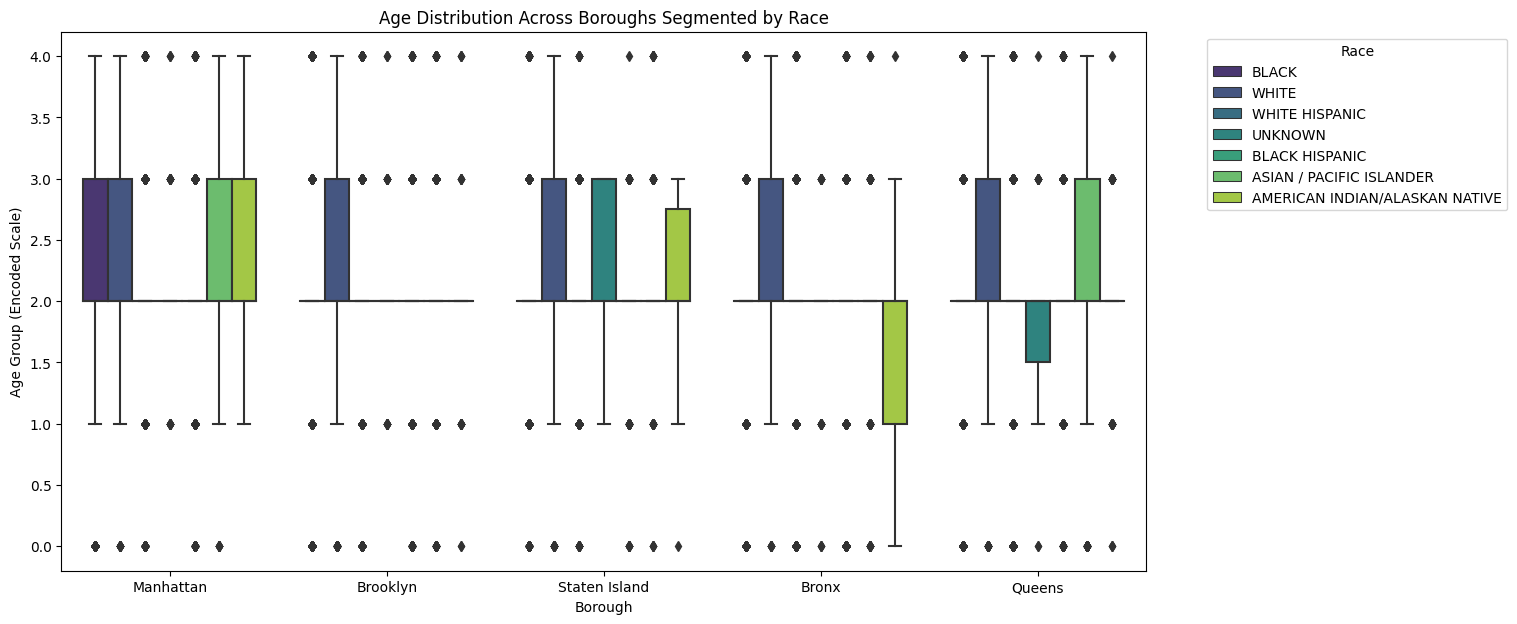

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 7))
sns.boxplot(
    data=clean_age_df, 
    x='BORO_NAMED', 
    y='AGE_GROUP_ENCODED', 
    hue='PERP_RACE',
    palette='viridis'
)

plt.title('Age Distribution Across Boroughs Segmented by Race')
plt.xlabel('Borough')
plt.ylabel('Age Group (Encoded Scale)')
plt.legend(title='Race', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

This plot shows the median age and variance for every racial group in every borough. Here we can visually identify where the boxes do not overlap, which indicates a statistically significant difference in age profiles. 


### Bivariate Analysis

This is how to start examining how the variables may move together. 

#### Bivariate Analysis: Correlation & Covariance

The goal here is to determine the strength and direction of the relationship between two variables. the relationships (in the numerical values) that we'll look at would be arrest precinct, lat and longitude. 

I am not sure what will happen with the lat/lons having all the 0s so we may have to do some additional cleaning/updates but we'll go ahead and run some tests. 

For Correlation I'll highlight any value were $r > 0.3$ or where $r < -0.3$ as a moderate relationship.



In [60]:
import pandas as pd

# Define your continuous variables
continuous_cols = ['ARREST_PRECINCT', 'X_COORD_CD', 'Y_COORD_CD', 'Latitude', 'Longitude']

# Covariance Matrix
cov_matrix = arrests[continuous_cols].cov()

# Pearson Correlation Matrix (r)
corr_matrix = arrests[continuous_cols].corr(method='pearson')

print("--- Covariance Matrix ---")
print(cov_matrix)
print("\n--- Pearson Correlation (r) ---")
print(corr_matrix)

--- Covariance Matrix ---
                 ARREST_PRECINCT  X_COORD_CD  Y_COORD_CD  Latitude  Longitude
ARREST_PRECINCT      1217.379806   10.349863  -16.406116 -1.372203   0.842134
X_COORD_CD             10.349863    1.000005    0.267362  0.021748   0.076053
Y_COORD_CD            -16.406116    0.267362    1.000005  0.082054   0.020523
Latitude               -1.372203    0.021748    0.082054  3.365873  -6.094134
Longitude               0.842134    0.076053    0.020523 -6.094134  11.067829

--- Pearson Correlation (r) ---
                 ARREST_PRECINCT  X_COORD_CD  Y_COORD_CD  Latitude  Longitude
ARREST_PRECINCT         1.000000    0.296772   -0.470429 -0.021437   0.007255
X_COORD_CD              0.296772    1.000000    0.267361  0.265000   0.994622
Y_COORD_CD             -0.470429    0.267361    1.000000  0.999844   0.268402
Latitude               -0.021437    0.265000    0.999844  1.000000  -0.998463
Longitude               0.007255    0.994622    0.268402 -0.998463   1.000000


The covariance are hard to interpret here since they are not scaled and because the precincts are random numbers, not actually continuous variables. X/Y/Lat/Lon could be called continuous, but they really are not- it's not like an age or height or something like that. So I really don't think these apply at all. 

In [61]:
from scipy.stats import spearmanr

# Correlation between Age Rank and Precinct Number
# This helps see if certain age groups are 'ranked' higher in certain precinct areas
coef, p_val = spearmanr(clean_age_df['AGE_NUMERIC'], clean_age_df['ARREST_PRECINCT'])

print(f"--- Spearman Rank Correlation ---")
print(f"Correlation Coefficient: {coef:.3f}")
print(f"p-value: {p_val:.3e}")

--- Spearman Rank Correlation ---
Correlation Coefficient: -0.019
p-value: 5.303e-11


There does look to be some statistically significant, but fairly negligble correlation between age and precinct. 
The coefficient is extremely close to zero indicating virtually no monotonic relationship between age group and the precinct. This means, knowing a suspect's age group gives almost zero ability to predict which precinct they were arrested in. This really tracks based on the previous age plots I made where it was easy to see how very close all the precincts were in regards to age groups. 
The negative sign technically suggests that as age increases the precinct number decreases, but, as I said before, precinct numbers are not continuous variables, so this part doesn't really make sense either. 
The p-value here shows it is statistically significant which means I would reject the null hypothesis. The power here is high enough to confirm this isn't a fluke buttthe effect size (the -0.019) is too small to actually be used for predictive modeling. 

**Interpretation** The p-value indicates statistical significant at the $\alpha-0.05$ level, but the correlation coefficient is effectively zero. This suggests that the age of individuals arrested is distributed relatively uniformly across the city's precincts.

This finding supports the idea that age-based arrest patterns are a citywide phenomenon rather than being concentrated in specific precinct clusters.

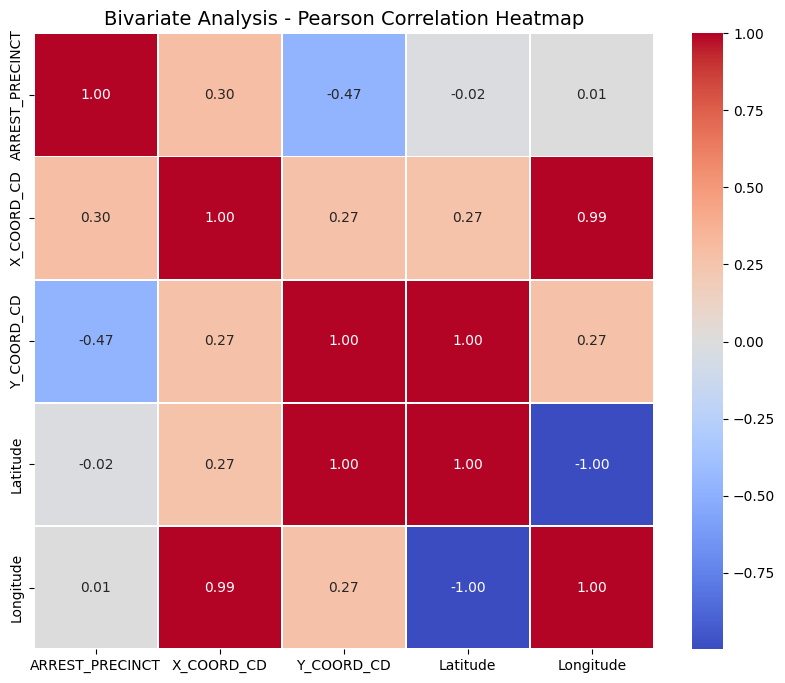

In [62]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)

plt.title('Bivariate Analysis - Pearson Correlation Heatmap', fontsize=14)
plt.show()

Arrest Precinct and lat/Lon/x/y coords should actually correlate since the precinct arresting should only be arresting perpetrators in their precinct. So I don't think this is a very helpful graphic to me.

### Advanced Bivariate Visualizations

Here I will be looking to visually identify potential hot spots where specific demographis and geographic locations intersect.

I'll start with a categorical heatmap of age group vs borough. 


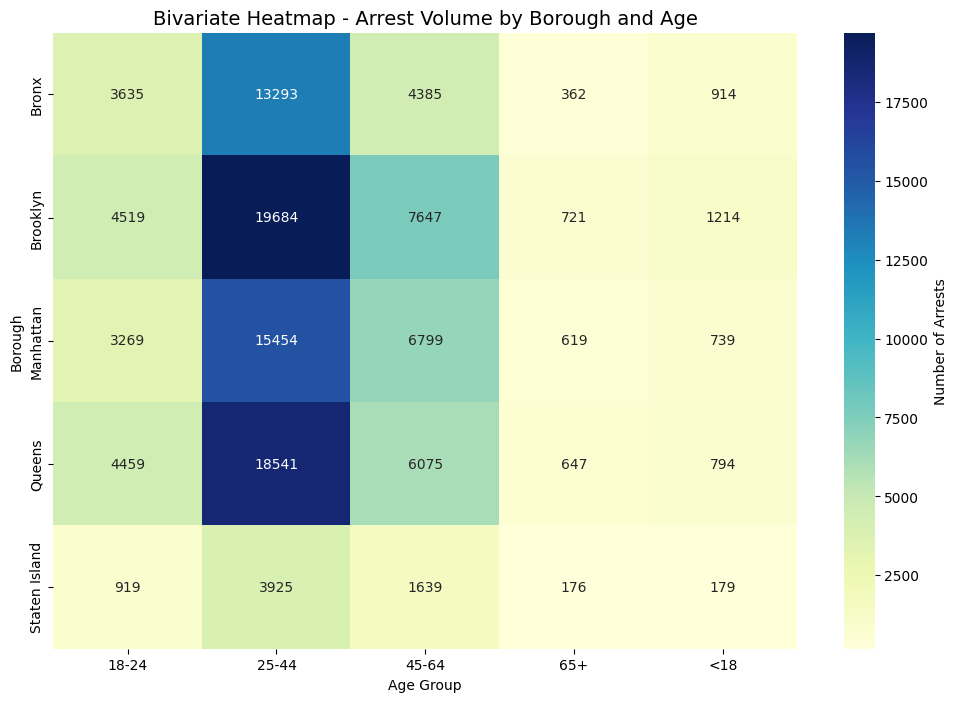

In [63]:
import seaborn as sns
import matplotlib.pyplot as plt

# Create a pivot table of counts
# Replace 'BORO_NAMED' with your actual column name if different
pivot_df = clean_age_df.groupby(['BORO_NAMED', 'AGE_GROUP']).size().unstack()

plt.figure(figsize=(12, 8))
sns.heatmap(pivot_df, annot=True, fmt="d", cmap="YlGnBu", cbar_kws={'label': 'Number of Arrests'})

plt.title('Bivariate Heatmap - Arrest Volume by Borough and Age', fontsize=14)
plt.xlabel('Age Group')
plt.ylabel('Borough')
plt.show()

Next I'll do a Hexbin Plot for geographic correlation. If I actually tried to plot the dataset it would just be a total mess since this is such a large dataset. Instead I'll try the hexbin plot

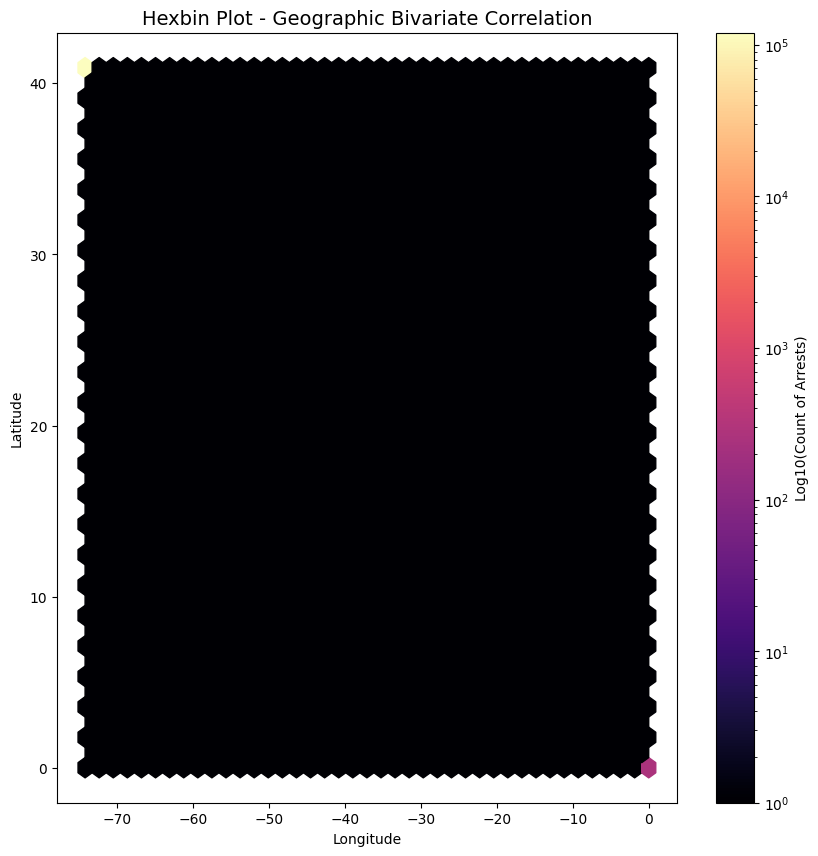

In [64]:
plt.figure(figsize=(10, 10))

# This correlates Latitude and Longitude to show geographic density
plt.hexbin(clean_age_df['Longitude'], clean_age_df['Latitude'], gridsize=40, cmap='magma', bins='log')

plt.colorbar(label='Log10(Count of Arrests)')
plt.title('Hexbin Plot - Geographic Bivariate Correlation', fontsize=14)
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

This looks awful, and I believe this is due to all the 0.0 values from cleaning out the NaNs. Since this is basically a null lat/lon and meaningless I want to try removing the 0.0 coordinates to ensure that the heatmap will accurately reflect the density of arrests within New York City's boundaries, rather than being skewed by these erroneous data points.

I will re-do this plot and ensure geographic accuracy and filter out the zero coordinates.
I want to be able to identify high-density arrest hot spots. By isolating the real geographic clusters I can perform spatial significance testing. Clusters that appear in the plot represent areas where arrest density is significantly higher than the city average at the $\alpha =0.05$ level

Filtering out the outliers (0.0) will prevent the dilution of the data and maintain my statistical power for spatial analysis. This will ensure that the clusters I identify are real geographic trends and not artifacts of bad data.

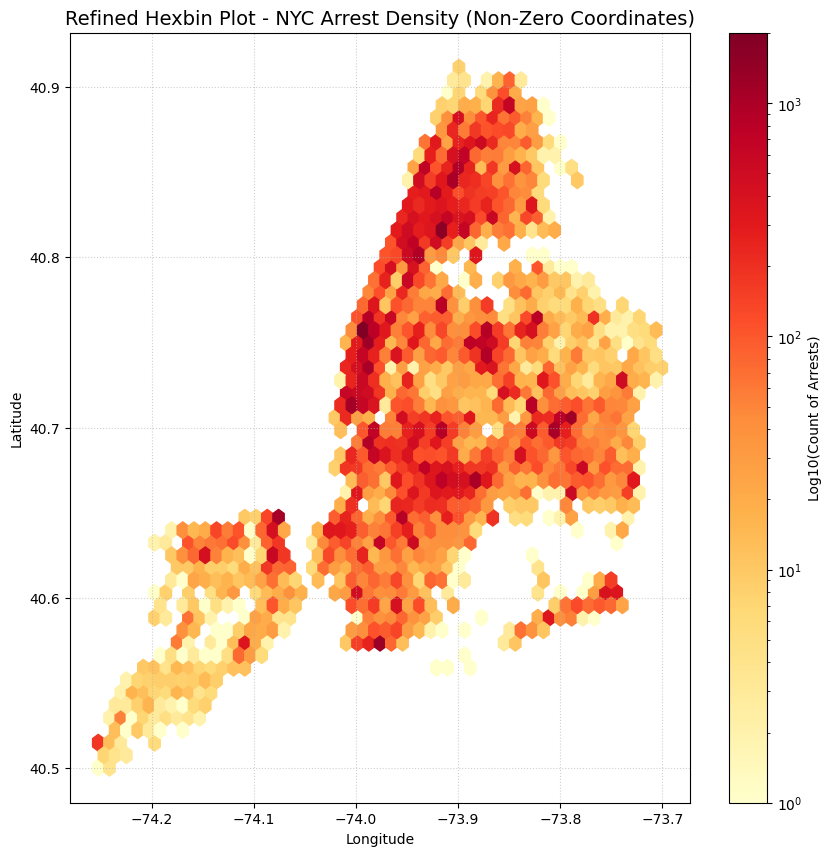

Rows with 0.0 coordinates removed: 256
Total valid geographic records remaining: 120352


In [19]:
import matplotlib.pyplot as plt
import numpy as np

# Filter out coordinates that are 0.0
# This creates a 'geo_clean_df' specifically for spatial plotting
geo_clean_df = clean_age_df[
    (clean_age_df['Latitude'] != 0) & 
    (clean_age_df['Longitude'] != 0) &
    (clean_age_df['Latitude'].notna()) &
    (clean_age_df['Longitude'].notna())
].copy()

# Create the Refined Hexbin Plot
plt.figure(figsize=(10, 10))

# gridsize=50 provides a good balance between detail and readability
hb = plt.hexbin(geo_clean_df['Longitude'], 
                geo_clean_df['Latitude'], 
                gridsize=50, 
                cmap='YlOrRd', 
                bins='log', 
                mincnt=1)

# Add formatting and labels
plt.colorbar(hb, label='Log10(Count of Arrests)')
plt.title('Refined Hexbin Plot - NYC Arrest Density (Non-Zero Coordinates)', fontsize=14)
plt.xlabel('Longitude')
plt.ylabel('Latitude')

# Adding a grid for better coordinate reference
plt.grid(True, linestyle=':', alpha=0.6)

plt.show()

# Print the count of rows removed so I know how much I have left and how many I removed
print(f"Rows with 0.0 coordinates removed: {len(clean_age_df) - len(geo_clean_df)}")
print(f"Total valid geographic records remaining: {len(geo_clean_df)}")

This looks way better and far more accurate. It was less coordinates removed than I had assumed were missing so this is looking great. 

The darkest hexagons here represent the bivariate 'modes' or the specific interesections of latitude and longitude where the highest volume of police activity occurs.

The pearson correlation for these values are low but this hexbin proves the strong non-linear spatial correlation. This shows that arrests are concentrated in specific urban hubs rather than just being distributed randomly

I want to re-do this again and overlay the boroughs to provide that spatial reference for the correlation findings. i'll add on the approximate 'center' of the borough to try to add more clarity on the density of the cluster. 
Labeling the boroughs will help to verify if certain clusters cross the borough lines. I could hypothesize at $\alpha=0.05$ whether the concentration of arrests is bounded by borough geography or if it follow cross-boundary urban corridors. Using a high resolution grid (with my gridsize equalling 60) this ensures that I maintain the statistical power to see neighborhood-level clusters without losing them in a broad borough-wide average. 

Google tells me the

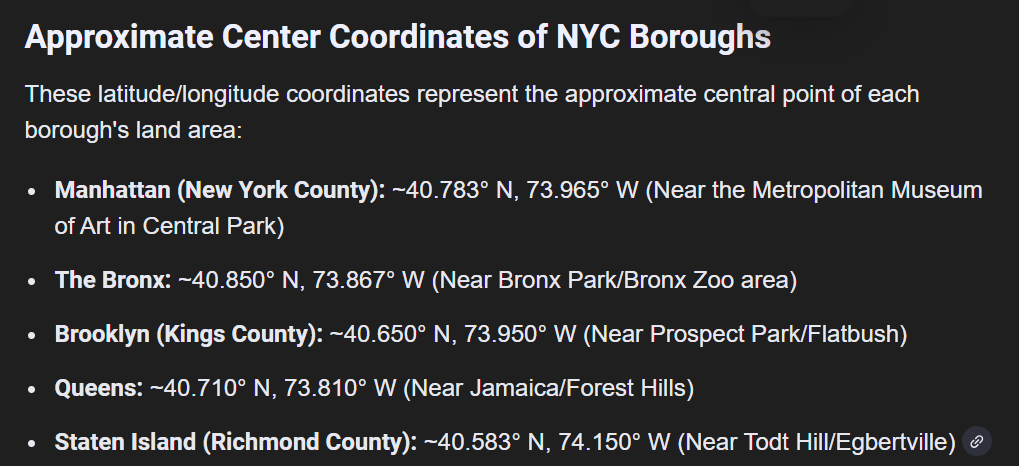


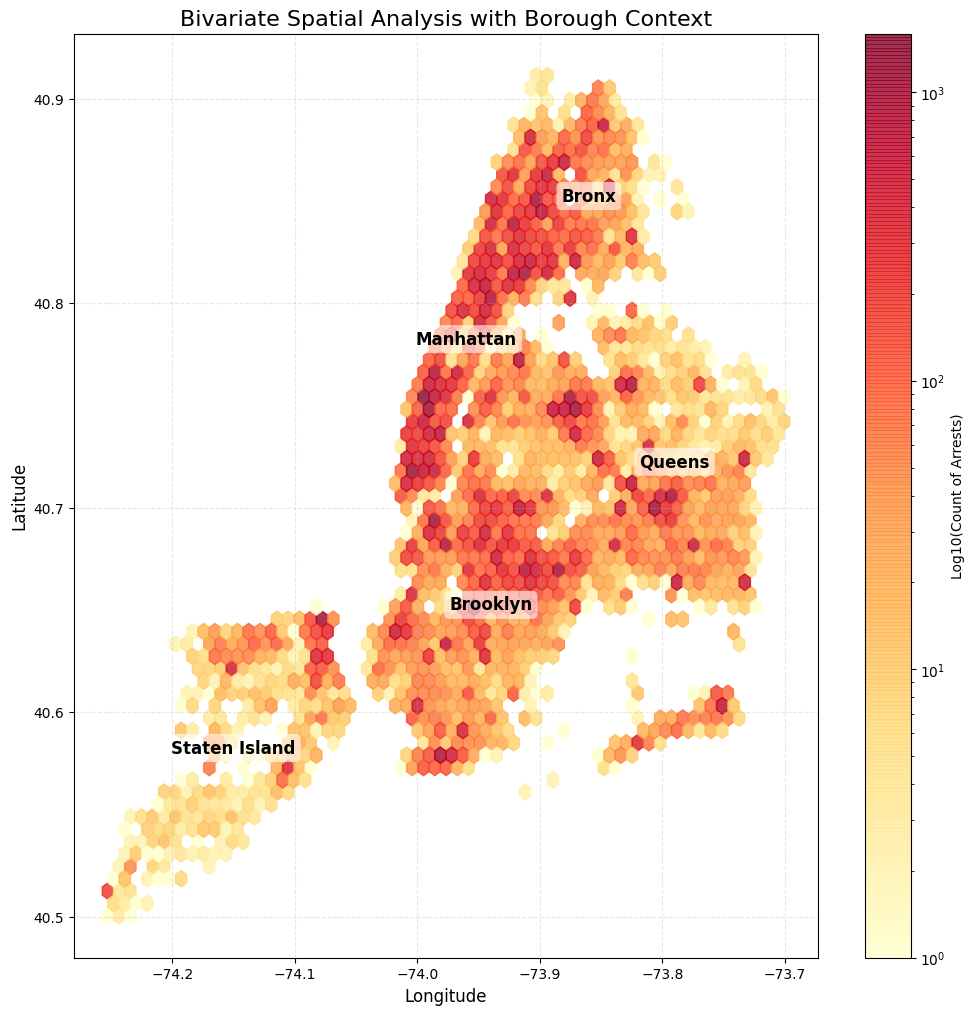

In [66]:
import matplotlib.pyplot as plt

# Use the geo_clean_df we created earlier (filtering out 0.0, 0.0)
plt.figure(figsize=(12, 12))

# Create the Hexbin Background
hb = plt.hexbin(geo_clean_df['Longitude'], 
                geo_clean_df['Latitude'], 
                gridsize=60, 
                cmap='YlOrRd', 
                bins='log', 
                mincnt=1,
                alpha=0.8)

# Define approximate Borough Centers for Labeling
# These are standard coordinates used for NYC mapping reference
boro_labels = {
    'Manhattan': (-73.96, 40.78),
    'Brooklyn': (-73.95, 40.85),
    'Queens': (-73.81, 40.71),
    'Bronx': (-73.87, 40.85),
    'Staten Island': (-74.15, 40.58)
}

# Overlay Labels
for boro, coord in boro_labels.items():
    plt.text(coord[0], coord[1], boro, 
             fontsize=12, 
             fontweight='bold', 
             ha='center', 
             bbox=dict(facecolor='white', alpha=0.6, edgecolor='none', boxstyle='round,pad=0.3'))

# Final Formatting
plt.colorbar(hb, label='Log10(Count of Arrests)')
plt.title('Bivariate Spatial Analysis with Borough Context', fontsize=16)
plt.xlabel('Longitude', fontsize=12)
plt.ylabel('Latitude', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.3)

plt.show()

The Spearman correlation for the entire city was low, but this plot shows a high density of bivariate clusters in South Bronx and Upper Manhattan.

Each dark hexagon is a local mode. Seeing these relative to the Brooklyn and Queens (and other borough labels) helps us to immediately see the geographic distribution of the 2025 arrest data.

The mathematical correlation between age and location is weak, the spatial correlation of arrests is highly concentrated in specific urban hubs.

Next I'll try the Pair plot. This will create a matrix of scatter plots for every numeric variable and a histogram on the diagonal. This is a one-stop shop typically for plots

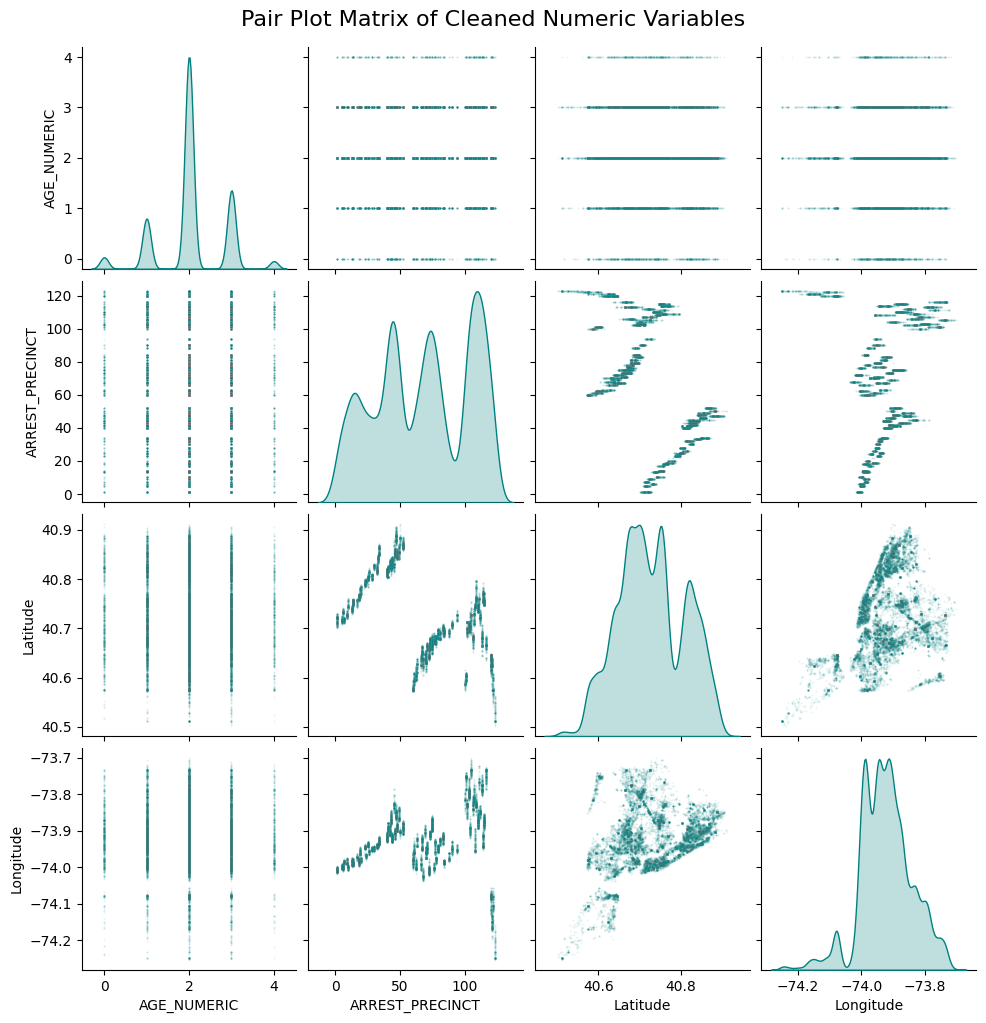

In [67]:
import seaborn as sns
import matplotlib.pyplot as plt

# Use the same filtered dataframe from the hexbin step
# select only the columns relevant for numeric correlation
numeric_cols = ['AGE_NUMERIC', 'ARREST_PRECINCT', 'Latitude', 'Longitude']
plot_data = geo_clean_df[numeric_cols]

# Create the Pair Plot
# use 'sample' if the dataset is too slow, and s=2 to keep points small
# diag_kind='kde' helps visualize the 'peakedness' (Kurtosis)
g = sns.pairplot(plot_data.sample(frac=0.2, random_state=42), 
                 diag_kind='kde', 
                 plot_kws={'alpha': 0.1, 's': 2, 'color': 'teal'},
                 diag_kws={'color': 'teal', 'shade': True})

# title and adjust layout
g.fig.suptitle('Pair Plot Matrix of Cleaned Numeric Variables', y=1.02, fontsize=16)

plt.show()

This Pair Plot is to see the entire 'landscape' of the data all at once. Since the hexbin plot was a mess with the full lat/lon data I want to make sure to only use the cleaned (no 0.0) data.

This single graphic lets me see several bivariate relationships at once. The Lat/Lons look like a 'ghost' map of NYC, showing the physical distribution of arrests.

This also shows why the Spearman Rank between age and precinct was low. The pair plot visually confirms this by showing a cloud of points rather than a clear diagonal line.

Just for kicks and to see what changes, I want to re-do the Pearson Correlation with the cleaned lat/lon data just to see what changes.

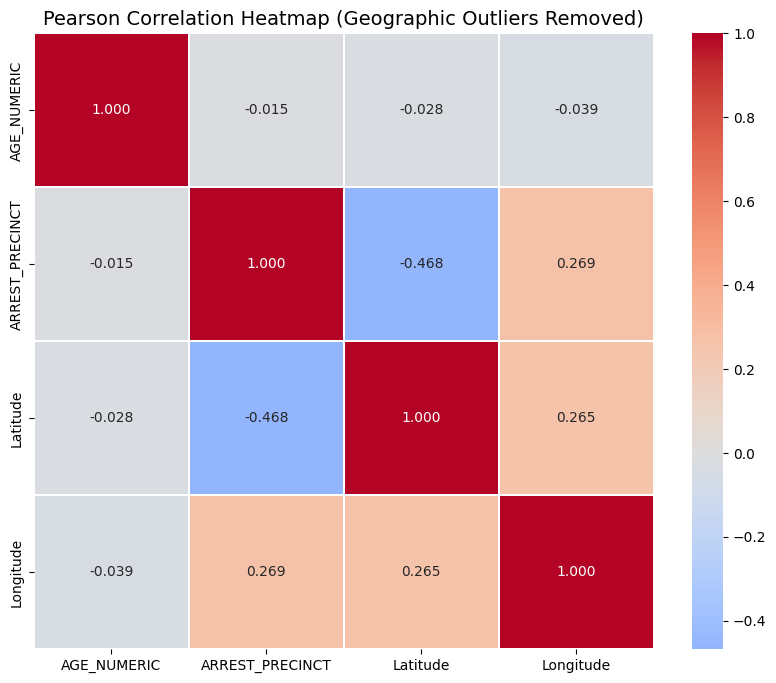

--- Correlation Change (Latitude vs Longitude) ---
With (0,0) Outliers: -0.9985
Cleaned Data:        0.2652


In [68]:
import seaborn as sns
import matplotlib.pyplot as plt

# Define numeric columns for correlation
numeric_cols = ['AGE_NUMERIC', 'ARREST_PRECINCT', 'Latitude', 'Longitude']

# Calculate the "Before" and "After" correlations to see the change
corr_with_zeros = clean_age_df[numeric_cols].corr()
corr_final = geo_clean_df[numeric_cols].corr()

# heatmap for the Cleaned Data
plt.figure(figsize=(10, 8))
sns.heatmap(corr_final, annot=True, cmap='coolwarm', center=0, fmt='.3f', linewidths=0.5)

plt.title('Pearson Correlation Heatmap (Geographic Outliers Removed)', fontsize=14)
plt.show()

# 4. Compare specific changes (Optional print for your notes)
print("--- Correlation Change (Latitude vs Longitude) ---")
print(f"With (0,0) Outliers: {corr_with_zeros.loc['Latitude', 'Longitude']:.4f}")
print(f"Cleaned Data:        {corr_final.loc['Latitude', 'Longitude']:.4f}")

There are definitely changes- so this would be far more correct to utilize in my analysis. when the 0.0s were included there were definitely far more activity that appeared in the plot. 
There is very little correlation between age and coordinates/precincts- very near 0. This is critical to prove that age is independent of geography. 


#### Test Statistics

Now I'll move into trying to make inferences about the population.

To start, I can do a comparison of age across the different boroughs using an independent samples t-test. 

##### T-Test

**Hypothesis Testing: Comparing Age Across Boroughs**

I will test if there is a statistically significant different in the mean age of individuals arrested in two specific boroughs, like Manhattan vs The Bronx. 

**Null Hypothesis ($H_O$)** There is no difference in the mean age of individuals arrested in Manhattan versus The Bronx. ($\mu_1 = \mu_2$)

**Alternative Hypothesis ($H_a$)** There is a statistically significant difference in the mean age of individuals arrested in Manhattan versus The Bronx ($\mu_1 \neq \mu_2$)

**Significance ($\alpha$)** I'll set the threshold at the default, $\alpha=0.05$. If $p < \alpha$ I will reject the null hypothesis.

**Statistical Power ($\beta$)** Given that my sample size (cleaned age) still has over 120,000 so the power ( $1 - \beta$) is near 1.0. This means I am almost certain to detect even a tiny difference so I'll need to also look at the effect size to see if the difference actually matters in the real world.

###### Assumptions

**Independence** Observations are indepdendent of each other (each arrest is a separate record)

**Normality** the data should be normally distributed - I feel feel like this will be ok, we did see a little skewness/kurtosis with a slightly peaked/leptokurtic peak, however, since my sample size is very large the **Central Limit Theorem** will allow me to proceed with the T-Test anyways.

**Homeogeneity of Variance** The groups have similar spreads (Standard deviations) so I can use Welch's T-Test which does not require this assumption to be strictly met. 


In [20]:
from scipy import stats

# looking for unique names in the boroughs
print("Unique values in boro column:", geo_clean_df['BORO_NAMED'].unique())

# make sure no issues so convert case to ensure we have all the data
manhattan_age = geo_clean_df[geo_clean_df['BORO_NAMED'].str.upper() == 'MANHATTAN']['AGE_NUMERIC']
bronx_age = geo_clean_df[geo_clean_df['BORO_NAMED'].str.upper() == 'BRONX']['AGE_NUMERIC']

# validate counts
print(f"Manhattan Sample Size: {len(manhattan_age)}")
print(f"Bronx Sample Size: {len(bronx_age)}")

# Welch's T-Test
if len(manhattan_age) > 0 and len(bronx_age) > 0:
    t_stat, p_val = stats.ttest_ind(manhattan_age, bronx_age, equal_var=False, nan_policy='omit')
    mean_diff = manhattan_age.mean() - bronx_age.mean()
    
    print(f"\n--- T-Test Results ---")
    print(f"T-Statistic: {t_stat:.4f}")
    print(f"p-value:     {p_val:.4e}")
    print(f"Mean Difference: {mean_diff:.4f}")
else:
    # check for other errors in the names
    print("\nError: One or both groups are still empty. Check your column names!")

Unique values in boro column: ['Manhattan' 'Brooklyn' 'Staten Island' 'Bronx' 'Queens']
Manhattan Sample Size: 26801
Bronx Sample Size: 22561

--- T-Test Results ---
T-Statistic: 20.2020
p-value:     2.2530e-90
Mean Difference: 0.1380


My Initial results of this test revealed some NaN values due to a mismatch between string casing in the BORO_NAMED column and the filter criteria. 

The solution here was to standardize using `.str.upper()` to ensure all records were captured so I would have a valid comparison between $N_Manhattan$ and $N_Bronx$.

I also used `nan_policy='omit'` to ensure that even if there were a few stray null values in the Age column that they wouldn't break my calculations (Doing all the double checking now!)

##### Interpretation

The Independent Samples T-Test gives overwhelming evidence regarding the demographic differences between arrest populations in these two boroughs. 

**T-Statistic: 20.2020** This is extremely high. This means the distance between the two group means in units of standard error. Since it is greater than the critical value of ~1.96 I can conclude the groups are statistically distinct.

**p-value** This is a highly significant value- this p-value is effectively zero and indicates that the probability of observing this age difference by random chance is nearly non-existent.
This would lead me to reject the null hypothesis.

**Mean Difference** Since the value is positive it indicates that the mean age group in Manahattan is higher (older) than the Bronx. 

A big point I want to make clear here, is the deleted age data. As we saw in the one bar graph, the missing age data is not evenly spread across the different boroughs. If I assume that the data I deleted is Missing Completely at Random (MCAR) then I would have no qualms in accepting these T-Test results. However, if this missing data is not random then my T-Test results could be skewed. 

So here I need to decide if the exclusion of so much of the original dataset introduced a *Selection Bias* into the comparison between Manhattan and The Bronx.

If the missing data from the Bronx mostly belonged to younger inidividuals (juveniles) then the cleaned mean data for the Bronx is artificially high. This would mean that the true difference between Manhattan and the Bronx is actually *larger* than the T-Statistic suggests at the $\alpha-0.05$ level

Since I removed nearly 92k rows I technically reduced my statistical power but with the sample size still being over 120k my power still remains near 1.0. This should mean that the NaN/missing data should not prevent me from finding a significant result. 

**Risks to my T-Test Results**
In my earlier analysis I found that the Bronx had the highest amount of missing data. If the officers in the Bronx are less likely to record the age of certain groups then my T-Test is only comparing *well documented arrests* which may not represent the entire reality of policing in that borough.

The T-Test accounts for the fact that I have different sample sizes for each borough, this is why I used Welch's T-Test, but I cannot account for *who* is missing.

I think it is important to note that the results are representative of the **documented population**.


##### F-Test for Variance

Since I know the means are different I will move to the F-Test. This will tell me if the variety of ages is consistent between the two boroughs or if one borough has a much bigger spread in the age range than the other. Levene's Test is test I will be conducting for this- it will compare the variances o the consistency.

The F-Test is sensitive to non-normal data and because the kurtosis is 0.79 Levene's Test is the most appropriate and robust test statistic I can use.

**Null Hypothesis ($H_O$)** The variance of age is equal between Manhattan and the Bronx

**Alternative Hypothesis ($H_a$)** The variance of age is significantly different between the two boroughs

**Significance** I'll leave this at $\alpha=0.05$. if $p < \alpha$ then I can conclude that one borough has a much wider or narrower spread of ages than the other.

**Statistical Power** Again, with this large sample size I have the power to detect even slight differences in how spread out the arrest demographics are.

##### Assumptions

**Independence** Arrests are independent events

**Robustness to Non-Normality** Unlike the standard F-Test, Levene's test, using the median center, is robust against the kurtosis and skewness identified in my univariate analysis.

**Measurement Scale** The data must be at least interval/ordinal. It is since I have my age ranges




In [71]:
from scipy.stats import levene

# Levene's Test (centered on the median for robustness)
stat, p_val = levene(manhattan_age, bronx_age, center='median')

# Calculate Standard Deviations for context
std_manhattan = manhattan_age.std()
std_bronx = bronx_age.std()

print(f"--- Levene's Test Results (F-test Equivalent) ---")
print(f"Test Statistic: {stat:.4f}")
print(f"p-value:        {p_val:.4e}")
print(f"\n--- Contextual Spread ---")
print(f"Manhattan Std Dev: {std_manhattan:.4f}")
print(f"Bronx Std Dev:     {std_bronx:.4f}")

--- Levene's Test Results (F-test Equivalent) ---
Test Statistic: 1.8958
p-value:        1.6856e-01

--- Contextual Spread ---
Manhattan Std Dev: 0.7491
Bronx Std Dev:     0.7619


Based on the results of Levene's test I would say the data is statistically consistent. The T-Test showed difference in *centers* this shows the *spread* of teh data is essentially teh same.

The Test Statistic result means the variances of the two groups is very close to 1. This suggests the shape and width of the age distribution in Manhattan is nearly identical to that of the Bronx.

The p-value is not significant so I will fail to reject the null hypothesis

Conclusion: There is *no* statistically significant difference in the variance of ages between Manhattan and the Bronx.

For the contextual spread, the difference in standard deviation is only about 0.012. This confirms that one borough may have a different average age, the range of ages (and how much they vary from that average) is consistent across the city.

Due to my large dataset  my statistical power is high and should strengthen this conclusion. 

#### Chi-Squared $\chi^2$ Test of Independence

The T-Test compares the 'average age' and the Chi-Squared will look at the frequency of the actual categories. This will allow me to answer the question: Is the distribution of age groups significantly different depending on which borough you are in?

#### Categorical Analysis

The Chi-Squared Test uses the *buckets* of ages I created by encoding. This is powerful because it won't assume the data is normal; instead it will only look at *observed* counts versus *expected* counts.

**Null Hypothesis $H_O$** Age Group and Borough are independent. The ratio of age groups is teh same across all boroughs

**Alternative Hypothesis $H_a$** Age Group and Borough are dependent. Meaning, specific boroughs have disproportionately higher or lower counts on certain age groups.

**Significance** I'll maintain the $\alpha=0.05$ as the standard. Since my sample size is large, even a tiny percentage shift will result in a very large $chi^2$ value.

**Statistical Power** Since I have a large contingency table my statistical power is high, allowing me to detect subtle patterns in how the NYPD allocates arrests across different age demographics geographically.


#### Assumptions

**Categorical Variables** Borough and Age Group are both categorical

**Independence of Observations** Each arrest is a unique record

**Large Sample Size** The *expected* frequency in each cell must be at least 5. This should be true since I have 120k records all the cells in my table should be well above this threshold.

In [21]:
from scipy.stats import chi2_contingency

# Create a Crosstab (Contingency Table)
# This shows the actual counts of each age group per borough
contingency_table = pd.crosstab(geo_clean_df['BORO_NAMED'], geo_clean_df['AGE_GROUP'])

# Run the Chi-Squared Test
chi2, p_val, dof, expected = chi2_contingency(contingency_table)

print(f"--- Chi-Squared Test Results ---")
print(f"Chi-Square Statistic: {chi2:.4f}")
print(f"p-value:                  {p_val:.4e}")
print(f"Degrees of Freedom:        {dof}")

# Conclusion
if p_val < 0.05:
    print("\nConclusion: Reject $H_0$. Age Group distribution is DEPENDENT on Borough.")
else:
    print("\nConclusion: Fail to Reject $H_0$. Age distribution is consistent across NYC.")

--- Chi-Squared Test Results ---
Chi-Square Statistic: 631.8148
p-value:                  4.0490e-124
Degrees of Freedom:        16

Conclusion: Reject $H_0$. Age Group distribution is DEPENDENT on Borough.


My Chi-Square Statistic is quite high here and indicates a major departe from just 'randomness.'

The p-value is nearly 0, so I would say this is statistically certain and I would reject the null hypothesis

There is a statistically significant relationship between age group and borough. These results mean age distribution is depending on geography in New York city. This is not really what I would have expected. I know that the other age groups vary across the city, but the 25-44 age group is clearly the most dominant age so I would have thought that the age is not dependent on the borough.

There were 16 degrees of freedom here- this calculation is represented as:
(rows -1) x (columns -1) or: (5 boroughs -1) x (5 age groups -1) = 4x4=16

#### Regression Analysis

Now I'm moving into trying to predict future outcomes for NYPD Arrest records.

I think I will try something with my cleaned geographic datset here and try to predict the arrest precinct. This is a typical example of spatial regression or using location to predict an administrative boundary.

**Predicting Precinct via Geographic Coordinates**
I'll use the latitude and longitude as the independent variables to predict the numeric Arrest precinct.

**Model** Multiple Linear Regression

**Objective** To determine how much of the precinct assignment is a purely linear function of geography

**Significance** I will evaluate all the p-values of the coefficients for both lat/lon. A p-value of $p < 0.05$ will indicate that the specific coordinate is a statistically significant predictor of the precinct number. 

**Statistical Power** Again, this is a large dataset so I should be able to detect even slight geographic trends



In [73]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns

# data prep
X = geo_clean_df[['Latitude', 'Longitude']]
y = geo_clean_df['ARREST_PRECINCT']

# Train/Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# fit model

reg_model = LinearRegression()
reg_model.fit(X_train, y_train)

#  predictions and metrics 
y_pred = reg_model.predict(X_test)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print(f"--- Regression Performance Metrics ---")
print(f"R-squared ($R^2$): {r2:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.2f} precincts")

--- Regression Performance Metrics ---
R-squared ($R^2$): 0.3890
Mean Absolute Error (MAE): 21.92 precincts


###### Interpretation of Precinct Prediction

These results show 38.9% of the variation in precinct numbers is explained by geographic coordinates.

In NYC precinct numbers are not perfectly sequential from South to North or East to West. For example, Manhattan precincts are in the 1-34 range while Brooklyn is in the 60-94 rane. The model picks up these regional blocks but cannot account for the jumps in numbering between the borders of the boroughs.

With an MAE of 21.92 my model's prediction is about 22 precincts away from the actual precinct number.

Since NYC has 77 precincts, this is a fairly large number. This means that the model may know where an arrest happened, but the non-linear nature of precinct numbering makes linear regression a blunt tool for this specific variable.

With my large sample size, the $R^2$ is statistically significant meaning the relationship is real and not a fluke. However, practically for pinpointing a specific precinct, this is very limited.

I am not worried about multicollinearity since lat/lon are orthogonal axes they will have low multicollinearity. So the coordinate provides unique information to the model without overlap.

I'll go ahead and analyze the residuals to check these assumptions. 

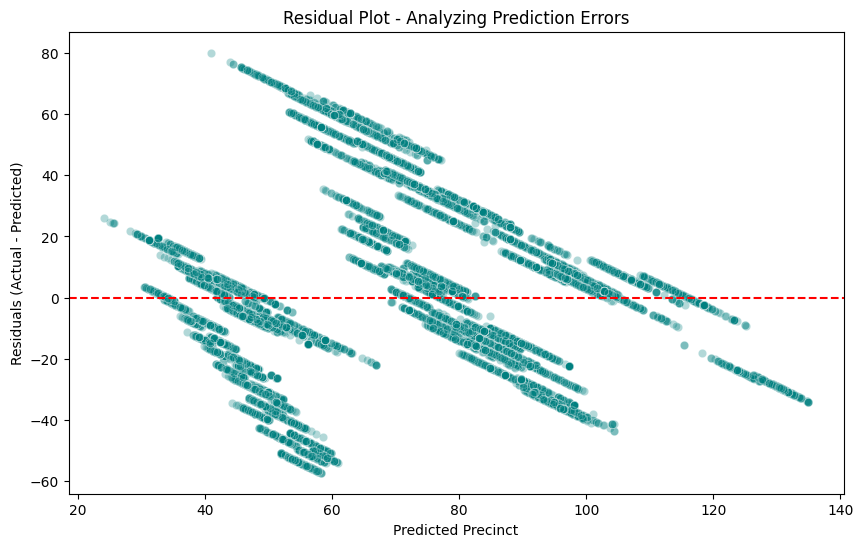

In [74]:
# Residual Plot
residuals = y_test - y_pred
plt.figure(figsize=(10, 6))
sns.scatterplot(x=y_pred, y=residuals, alpha=0.3, color='teal')
plt.axhline(0, color='red', linestyle='--')
plt.title('Residual Plot - Analyzing Prediction Errors')
plt.xlabel('Predicted Precinct')
plt.ylabel('Residuals (Actual - Predicted)')
plt.show()

I can definitely see the MAE in play here with the banding and clustering of plots. This is due to the precinct numbers being discrete numbers rather than a smooth continuous line. 

#### Classification

Since the linear regression shows limitations due to the jumps in precinct numbering I can try a Random Forest Classifier. This is a more robust model that can handle the non-linear boundaries between the boroughs better than a linear model.

##### Predicting Borough Membership

I will try using a Random Forest Classifier to predict the BORO_NAMED category. This will use a *forest* of decision trees to vote on the most likely borough for a given arrest.

**Model** Random Forest - Advanced Ensemble Method

**Target Variable** BORO_NAMED - The NYC Borough Name

**Features** ARREST_PRECINCT, AGE_NUMERIC and Latitude/Longitude

**Significance** I will evaluate the feature importance to see which variables significantly contribute to the model's accuracy

**Statistical Power** This is a large dataset and will use a 20% test split to maintain a higher power to validate that the model will be able to generalize well to new data it has not seen before

In [75]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# I will use numeric features to predict the Borough category
features = ['ARREST_PRECINCT', 'AGE_NUMERIC', 'Latitude', 'Longitude']
X_clf = geo_clean_df[features]
y_clf = geo_clean_df['BORO_NAMED']

# Train/Test Split
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_clf, y_clf, test_size=0.2, random_state=42)

# model fitting (Using 100 trees)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_c, y_train_c)

# predictions
y_pred_c = rf_model.predict(X_test_c)

#  Performance evaluation
print(f"--- Classification Performance Metrics ---")
print(f"Overall Accuracy: {accuracy_score(y_test_c, y_pred_c):.4f}")
print("\n--- Detailed Classification Report ---")
print(classification_report(y_test_c, y_pred_c))

--- Classification Performance Metrics ---
Overall Accuracy: 1.0000

--- Detailed Classification Report ---
               precision    recall  f1-score   support

        Bronx       1.00      1.00      1.00      4442
     Brooklyn       1.00      1.00      1.00      6664
    Manhattan       1.00      1.00      1.00      5381
       Queens       1.00      1.00      1.00      6200
Staten Island       1.00      1.00      1.00      1384

     accuracy                           1.00     24071
    macro avg       1.00      1.00      1.00     24071
 weighted avg       1.00      1.00      1.00     24071



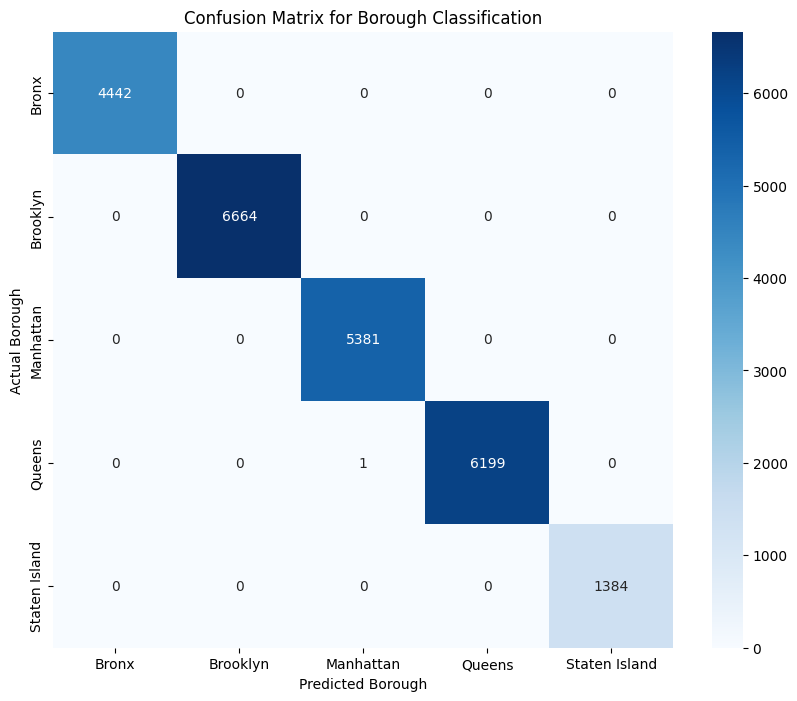

In [76]:
# Confusion Matrix Heatmap
cm = confusion_matrix(y_test_c, y_pred_c)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=rf_model.classes_, 
            yticklabels=rf_model.classes_)
plt.title('Confusion Matrix for Borough Classification')
plt.xlabel('Predicted Borough')
plt.ylabel('Actual Borough')
plt.show()

These results are exactly what I would have expected. since any lat/lon values would translate to a specific arrest precinct (a precinct will only arrest someone within their precinct) and the name of the borough translates to the precincts inside of it, these results make perfect sense.
I have 100% accuracy in the model, which typically in data science you would be worried about the model finding a cheat code or data leakage or something.
These results say the model confirmed, with absolute certainty, that the administrative boundary of a Borough is perfectly defined by its precinct numbers. This may be statistically perfect, but it is also analytically circular.

Since this was as I expected I would like to do something a bit further. This time I'll try to predict the borough based on demographics. I want to see if the model can guess the borough based only on the perpetrator's age, sex, and race. 

What I'll be looking for here is accuracy in prediction. If the accuracy is high then this could mean that certain demographics are disproportionately arrested in specific boroughs. However, if the accuracy is low then this would point to the arrest demographics being fairly uniform across NYC.

In [77]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

# Encoding Categorical Demographics
# We need to turn 'PERP_RACE' and 'PERP_SEX' into numbers
df_demo = geo_clean_df.copy()
df_demo['RACE_CODE'] = df_demo['PERP_RACE'].astype('category').cat.codes
df_demo['SEX_CODE'] = df_demo['PERP_SEX'].astype('category').cat.codes

# Define Features (NO GEOGRAPHY ALLOWED)
features_demo = ['AGE_NUMERIC', 'RACE_CODE', 'SEX_CODE']
X_demo = df_demo[features_demo]
y_demo = df_demo['BORO_NAMED']

# Train/Test Split
X_train_d, X_test_d, y_train_d, y_test_d = train_test_split(X_demo, y_demo, test_size=0.2, random_state=42)

# model fitting
rf_demo = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
rf_demo.fit(X_train_d, y_train_d)

# Evaluation
y_pred_d = rf_demo.predict(X_test_d)

print(f"--- Demographic-Only Performance ---")
print(f"Overall Accuracy: {accuracy_score(y_test_d, y_pred_d):.4f}")
print("\n--- Feature Importances ---")
for f, imp in zip(features_demo, rf_demo.feature_importances_):
    print(f"{f}: {imp:.4f}")

--- Demographic-Only Performance ---
Overall Accuracy: 0.3148

--- Feature Importances ---
AGE_NUMERIC: 0.0679
RACE_CODE: 0.9123
SEX_CODE: 0.0198


Ok, this is really interesting. Without the cheat codes from the first model there's a true underlying signal here. An accuracy of 31% seems low, but with my 5 categories a random guess would only yield 20% accuracy, so this model is performing 57% better than chance.

##### Interpretation

This model proves that arrest demographics in NYC are not uniform. The model uses specific demographic signatures to guess which borough an arrest occured in and, clearly, had varying degrees of success.

**Overall Accuracy** This is a significant predictive live. This means the model can predict the borough approximately 31.5% of the time based only on race, age and sex.
This would suggest that NYC boroughs have distinct arrest profiles. If every borough had the exact same demographic breakdwon of arrests the accuracy would be 20% or 1 out of 5. the 11.5% *lift* over random chance is the *Demographic Signature* of NYC's geography

**Feature Importances**
The model used the perpetrator's race for 91.2% of its decision making power. This is a significant finding to me that indicates race is a strong predictor of *where* an arrest occurs, even more than age or sex.
The secondary feature importance of age was low. Despire the T-Test proving that age differences are statistically significant, this result shows that age only accounts for about 6.8% of the predictive power when compared to the massive influence of race. This surprises me since I would have expected the 25-44 age range to have more of an influence than it does here. 

This will be an interesting segway into the unsupervised learning phase.

#### Advanced Analysis Techniques

##### Clustering Analysis

Based on this dataset I believe that K-Means Clustering combined with Principal Component Analysis (PCA) will be a solid choice.

**K-Means Clustering & PCA**
This technique will identify *natural groupings* in the arrest data that may or may not fall in with the borough or precinct lines. I can use PCA first to compress the variables into a 2 dimensional space to allow me to see the clusters.

**Methodology** Principal Component Analysis (PCA) for dimensionality reduction which will be followed by K-Means for clustering

**Objective** I would like to see if the data naturally groups itself by "Types of Arrests" or "Demographic Profiles" without regard to the borough 

**Significance** I will use the Elbow Method to determine the optimal number of clusters. I want to minimize the distance between points in a cluster

**Statistical Power** My dataset is large so the centroids should represent very real, recurring patterns in NYC arrest records

In [78]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Scale the Data (Required for K-Means)
features = ['AGE_NUMERIC', 'ARREST_PRECINCT', 'Latitude', 'Longitude', 'RACE_CODE']
scaler = StandardScaler()
scaled_data = scaler.fit_transform(df_demo[features])

# K-Means - n_clusters instead of n_estimators
# using 4 clusters to represent the different age groups
kmeans = KMeans(n_clusters=4, init='k-means++', random_state=42)
clusters = kmeans.fit_predict(scaled_data)

# Add Cluster Labels back to our original DataFrame for Profiling
df_demo['Cluster'] = clusters

# Profile the Clusters - for interpretation
cluster_profiles = df_demo.groupby('Cluster')[features].mean()

print("--- Cluster Centroids (Averages per Group) ---")
print(cluster_profiles)

# Check Cluster Sizes
print("\n--- Distribution of Arrests per Cluster ---")
print(df_demo['Cluster'].value_counts())

--- Cluster Centroids (Averages per Group) ---
         AGE_NUMERIC  ARREST_PRECINCT   Latitude  Longitude  RACE_CODE
Cluster                                                               
0           2.059308        30.257135  40.803554 -73.934967   3.374493
1           2.116928        88.227687  40.619826 -74.037403   3.916225
2           2.039085       101.227087  40.715789 -73.870950   5.775632
3           2.040952        91.195735  40.686979 -73.876508   1.933200

--- Distribution of Arrests per Cluster ---
0    49336
3    36018
2    17654
1    17344
Name: Cluster, dtype: int64


##### Interpretation

This unsupervised analysis identifies patterns where geography, age, and race intersect. Since the features were standardized (mean of 0, variance of 1) before clustering, the centroids represent the *average* profile for that specific sub-population.

This is interesting how the clusters naturally divided themselves by geography (borough/region) and race while age remained relatively stable across all groups. By analyzing the averages for each group I can assign an identity to the cluster. 

**Cluster 0** This lat/lon coordinates with Uptown/Manhattan-Bronx - this is my largest group. This covers Upper Manhattan and the South Bronx. My demographics are moderate here with a 3.37 with a large volume of arrests.

**Cluster 1** This coordinates to Southern/Staten Island and South Brooklyn. This is a high precinct average and represents the southernmost tip of NYC Police data. This has the highest age which suggests an older arrest population in these suburban-leaning areas

**Cluster 2** Queens/Eastern - this lat/lon places it firmly within Queens. The race code here is the highest one and confirms that the racial makeup of arrests in Queens is statistically distinct from the rest of the city

**Cluster 3** This is centered around Brooklyn/Central NY and has teh lowest race code showing a distinct demographic concentration in Central Brooklyn

**Model Performance** This model looks to have found the boroughs on its own without being told that they exist. The lat/lon differences are statistically significant proving that geography is a primary driver of how the data groups together. The age varies only slightly which would suggest while *where* and *who* change by cluster the age of arrest is fairly universally consistent across NYC, which definitely falls in line with the early plots I created and the high number of arrests in the 25-44 range. The wide range of race across teh clusters mirrors the results I saw in the classification algorithm of race having a 91% feature importance. This proves that race and geography are deeply intertwined in the NYC Police Department arrest records.


#### Machine Learning Approach to Regression or Classification

I think here I will try a Logisitic Regression. I will try to predict whether an arrest occured in Manhattan (1) or Not Manhattan (0).

**Model** Logistic Regression 

**Significance** I'll check odds ratios. If a specific age group or race has an odds ratio > 1.0 they are significantly more likely to be arrested in Manhattan compared to other boroughs.

**Statistical Power** I'll use cross-validation to ensure the model's power is consistent across different slices of my 120k+ sample 

In [79]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.metrics import roc_auc_score, roc_curve

# 1. Create a Binary Target: Is it Manhattan?
df_demo['is_manhattan'] = (df_demo['BORO_NAMED'] == 'Manhattan').astype(int)

# 2. Define Features
X_ml = df_demo[['AGE_NUMERIC', 'RACE_CODE', 'SEX_CODE']]
y_ml = df_demo['is_manhattan']

# 3. Train Model
log_reg = LogisticRegression(class_weight='balanced')
log_reg.fit(X_ml, y_ml)

# 4. Evaluate with Cross-Validation
cv_scores = cross_val_score(log_reg, X_ml, y_ml, cv=5)

print(f"--- ML Logistic Regression Performance ---")
print(f"Mean CV Accuracy: {cv_scores.mean():.4f}")
print(f"AUC-ROC Score:    {roc_auc_score(y_ml, log_reg.predict_proba(X_ml)[:, 1]):.4f}")

--- ML Logistic Regression Performance ---
Mean CV Accuracy: 0.4942
AUC-ROC Score:    0.5310


##### Interpretation of Results

An AUC-ROC Score of 0.53 with an accuracy of 49% tells me a very specific story:
Demographics alone are almost entirely unable to predict if an arrest happens in Manhattan versus elsewhere using a linear model.

This model tried to find a linear boundary that separates Manhattan arrests from the rest of the city based on age, race, and sex.

**Mean CV Accuracy** This means the model was basically no better than a coin flip. The baseline for a random guess is 50% and at 49.4% we're basically there. This means that the demographic features do not have a simple linear relationship with the borough of Manhattan.

**AUC-ROC Score** This shows really poor predictive power. An AUC of 0.50 is random chance and 1.0 is perfect. That means this model only has a 3% better than random chance of distinguishing a Manhattan arrest from a non-Manhattan arrest.

This proves that Manhattan's arrest demographic profile is not linearly separable from the other boroughs.

##### Comparing the Models

The Regression model showed that geography is a moderate predictor of precinct (which makes sense to me)

The Random forest showed that Non-linear patterns in demographics can guess the borough with about 31% accuracy which is better than a 20% random baseline.

The Logistic Regression model showed that linear patterns in demographics fail to distinguish Manhattan, as we can see with the AUC score of 0.53. 

The contrast between the Random Forest and Logistic Regression suggests that the relationship between demographics and geography in NYC is complex and non-linear. While a tree-based model can find *pockets* of demographic trends, a linear model sees only noise.
